# FFM-OSLO v2.3 — three-database training (CARLab + HUTUBS + SONICOM)

The architecture is still only **FFM + FiLM** — nothing else. Changes relative to v2.1/2.2:

| # | Change | Notes |
|---|---|---|
| 1 | All three databases enabled | `num_datasets` becomes 3 automatically, so FiLM grows to 3 rows |
| 2 | **Cell 3b — sampling weights** (new standalone cell) | The only place the mix is tuned. Re-run this one cell to change it; the split is not rebuilt |
| 3 | Checkpoint prefix changed to `FFM23_` | Does not overwrite the single-database run's `FFM21_*` |
| 4 | **The split file stays `split_v21.json`** | ⚠️ Do not rename it. The CARLab split is unchanged subject by subject and the new databases are only appended — that is what makes "single-database vs three-database on the same CARLab test set" a clean comparison |
| 5 | Carries over the configuration fixed in the single-database stage | `flatten_bins=0`, `band_lo_hz=0`, bf16 AMP, TF32, `save_after/save_every`, `resume_lr_mult` |

**Trained from scratch — no warm start.** The single-database result (CARLab-only, 150 epochs, val 1.403 dB)
and this run are two independent from-scratch trainings, same seed and same number of epochs, compared on the
same CARLab val/test — the only comparison that can support "pooling helps".

**Decision rule**: the 44-ear validation set resolves about **0.1 dB** (measured: two 22-ear halves differ by 0.19 dB).
Any difference smaller than that is treated as noise.

In [ ]:
# ==========================================================================
# Cell 0 — data preparation
#
# Two zip layouts are mixed, told apart by the folder names in dirs; the code path is the same (recursive search):
#   CARLab  : ELEC5021/CARLab/*_left.zip + *_right.zip  ->  CARLab_44k1_left/right
#   other two : ELEC5020/<db>.zip (single file)              ->  npy_left / npy_right
#
# id fixes the FiLM row index — never reorder it once a model has been trained.
# ==========================================================================
import os, zipfile
from google.colab import drive

drive.mount('/content/drive')

DRIVE = '/content/drive/MyDrive'
BASE = '/content/dataset'

DATASETS_SPEC = [
    dict(id=0, tag='CARLab',
         zips=[f'{DRIVE}/ELEC5021/CARLab/CARLab_44k1_left.zip',
               f'{DRIVE}/ELEC5021/CARLab/CARLab_44k1_right.zip'],
         extract_to=f'{BASE}/carlab',
         dirs=('CARLab_44k1_left', 'CARLab_44k1_right'),
         split=(0.80, 0.10, 0.10)),
    dict(id=1, tag='HUTUBS',
         zips=[f'{DRIVE}/ELEC5020/HUTUBS.zip'],
         extract_to=f'{BASE}/hutubs',
         dirs=('npy_left', 'npy_right'),
         split=(0.60, 0.15, 0.25)),          # ships 58 meshes -> keep a larger test set
    dict(id=2, tag='SONICOM',
         zips=[f'{DRIVE}/ELEC5020/SONICOM.zip'],
         extract_to=f'{BASE}/sonicom',
         dirs=('npy_left', 'npy_right'),
         split=(0.75, 0.10, 0.15)),
]

KNOWN_SUFFIX = ['_left_full.npy', '_left.npy', '_Left.npy', '_L.npy', '-left.npy']
L2R = [('_left_full', '_right_full'), ('_left', '_right'), ('_Left', '_Right'),
       ('-left', '-right'), ('_L.', '_R.')]


def find_dir(root, target):
    """Recursively find a folder named target, skipping __MACOSX; take the one with the most .npy"""
    cands = []
    for dp, _, fns in os.walk(root):
        if '__MACOSX' in dp:
            continue
        if os.path.basename(dp) == target:
            cands.append((sum(f.endswith('.npy') for f in fns), dp))
    cands.sort(reverse=True)
    return cands[0][1] if cands else None


def detect_suffix(d):
    """Detect the suffix in '<subject_id><suffix>'. Try the common ones, else fall back to the longest common suffix."""
    names = sorted(f for f in os.listdir(d) if f.endswith('.npy'))
    assert names, f'no .npy in {d}'
    for s in KNOWN_SUFFIX:
        if all(n.endswith(s) for n in names):
            return s, names
    s = names[0]
    for n in names[1:]:
        i = 0
        while i < min(len(s), len(n)) and s[-1 - i] == n[-1 - i]:
            i += 1
        s = s[len(s) - i:]
    return s, names


def right_of(sl):
    for a, b in L2R:
        if a in sl:
            return sl.replace(a, b)
    return None


DATASETS = []
for spec in DATASETS_SPEC:
    tag, out = spec['tag'], spec['extract_to']
    os.makedirs(out, exist_ok=True)
    ok = True
    for zp in spec['zips']:
        if os.path.exists(zp):
            with zipfile.ZipFile(zp) as z:
                z.extractall(out)
        else:
            print(f'[{tag}] * not found: {zp}'); ok = False
    if not ok:
        continue

    dl, dr = spec['dirs']
    ld, rd = find_dir(out, dl), find_dir(out, dr)
    if ld is None or rd is None:
        print(f'[{tag}] * {dl} / {dr} not found after extraction — check the zip layout')
        continue

    sl, ln = detect_suffix(ld)
    sr = right_of(sl)
    rn = sorted(f for f in os.listdir(rd) if f.endswith('.npy'))
    if sr is None or not all(n.endswith(sr) for n in rn):
        sr, rn = detect_suffix(rd)

    ids_l = {n[:-len(sl)] for n in ln}
    ids_r = {n[:-len(sr)] for n in rn}
    assert all(ids_l) and len(ids_l) == len(ln), \
        f'{tag}: suffix {sl!r} mis-detected — empty or duplicate subject ids'
    common = sorted(ids_l & ids_r)

    print(f"[{tag}] id={spec['id']}  left {len(ln)} / right {len(rn)}  "
          f'suffix {sl!r} / {sr!r}  both ears {len(common)} subjects')
    print(f'         {ld}')
    print(f'         id examples: {common[:4]} ... {common[-2:]}')
    if ids_l ^ ids_r:
        print(f'         ⚠️ {len(ids_l ^ ids_r)} subjects have one ear only (skipped): '
              f'{sorted(ids_l ^ ids_r)[:6]}')

    DATASETS.append(dict(id=spec['id'], tag=tag, left=ld, right=rd,
                         suffix=(sl, sr), split=spec['split']))

DATASETS = sorted(DATASETS, key=lambda d: d['id'])
assert DATASETS, 'no database loaded successfully'
assert [d['id'] for d in DATASETS] == list(range(len(DATASETS))), (
    f"ids must run contiguously from 0, got {[d['id'] for d in DATASETS]} — "
    'if a database is dropped, renumber the later ids in DATASETS_SPEC')

MIRROR_SRC = next((p for p in (
    f'{DRIVE}/ELEC5021/analysis/healpix_mirror_idx.npy',   # ← 现在的位置
    f'{DRIVE}/HRTF_Checkpoints/healpix_mirror_idx.npy',    # healpix_mirror.py 的旧输出
    f'{DRIVE}/healpix_mirror_idx.npy')                     # 更早的根目录版
    if os.path.exists(p)), f'{DRIVE}/ELEC5021/analysis/healpix_mirror_idx.npy')
print(f"\n{len(DATASETS)} databases | mirror idx: "
      f"{'found' if os.path.exists(MIRROR_SRC) else '* missing, Cell 3 will build it'}")

# ---- sample-rate reminder: Cell 1 verifies against meta.json; without it there is no check ----
no_meta = [d['tag'] for d in DATASETS
           if not os.path.exists(os.path.join(d['left'], 'meta.json'))]
if no_meta:
    print(f'\n⚠️ no meta.json in these databases, Cell 1 cannot verify the sample rate: {no_meta}')
    print('   All three must be 44.1 kHz / 256-point / 129 bins. At 48 kHz df = 187.5 Hz,')
    print('   at 44.1 kHz df = 172.27 Hz — the same bin index is off by 8%, which in the')
    print('   notch band is nearly 1 kHz. Mixing them raises no error, it just quietly degrades.')


Mounted at /content/drive
[CARLab] id=0  left 218 / right 218  suffix '_left_full.npy' / '_right_full.npy'  both ears 218 subjects
         /content/dataset/carlab/CARLab_44k1_left
         id examples: ['CL001', 'CL002', 'CL003', 'CL004'] ... ['CL217', 'CL218']
[HUTUBS] id=1  left 96 / right 96  suffix '_left_full.npy' / '_right_full.npy'  both ears 96 subjects
         /content/dataset/hutubs/HUTUBS/npy_left
         id examples: ['HU_pp1', 'HU_pp10', 'HU_pp11', 'HU_pp12'] ... ['HU_pp95', 'HU_pp96']
[SONICOM] id=2  left 399 / right 399  suffix '_left_full.npy' / '_right_full.npy'  both ears 399 subjects
         /content/dataset/sonicom/SONICOM/npy_left
         id examples: ['SON_P0001', 'SON_P0002', 'SON_P0003', 'SON_P0004'] ... ['SON_P0404', 'SON_P0405']

3 databases | mirror idx: * missing, Cell 3 will build it

⚠️ no meta.json in these databases, Cell 1 cannot verify the sample rate: ['HUTUBS', 'SONICOM']
   All three must be 44.1 kHz / 256-point / 129 bins. At 48 kHz df = 187.5

In [ ]:
!pip install healpy -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.5/8.5 MB 75.4 MB/s eta 0:00:00


assumed: fs=44100 Hz, nfft=256, 129 bins, df=172.266 Hz, fmax=22050 Hz
  CARLab-left       218 files | shape (129, 3072) OK | fs=44100 nfft=256
  CARLab-right      218 files | shape (129, 3072) OK | fs=44100 nfft=256
  HUTUBS-left        96 files | shape (129, 3072) OK | (no meta.json, sample rate unverified)
  HUTUBS-right       96 files | shape (129, 3072) OK | (no meta.json, sample rate unverified)
  SONICOM-left      399 files | shape (129, 3072) OK | (no meta.json, sample rate unverified)
  SONICOM-right     399 files | shape (129, 3072) OK | (no meta.json, sample rate unverified)
⚠️ no meta.json: ['HUTUBS', 'SONICOM'] — verify the sample rate from the plot below

Mean level per database, dB relative to its own 1-8 kHz (compare shapes across rows; the vertical offsets are absorbed by FiLM)
  DB        0.2-0.5k   0.5-2k     2-6k    6-12k   12-16k   16-18k18-22.05k   1-8k abs
  CARLab        -2.9     -1.4      1.9     -5.6     -8.0    -37.5    -51.7        3.5
  HUTUBS        -1.8  

/tmp/ipykernel_1719/2626216493.py:80: UserWarning: Glyph 26041 (\N{CJK UNIFIED IDEOGRAPH-65B9}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1719/2626216493.py:80: UserWarning: Glyph 21521 (\N{CJK UNIFIED IDEOGRAPH-5411}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1719/2626216493.py:80: UserWarning: Glyph 24179 (\N{CJK UNIFIED IDEOGRAPH-5E73}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1719/2626216493.py:80: UserWarning: Glyph 22343 (\N{CJK UNIFIED IDEOGRAPH-5747}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1719/2626216493.py:80: UserWarning: Glyph 24133 (\N{CJK UNIFIED IDEOGRAPH-5E45}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1719/2626216493.py:80: UserWarning: Glyph 24230 (\N{CJK UNIFIED IDEOGRAPH-5EA6}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1719/26

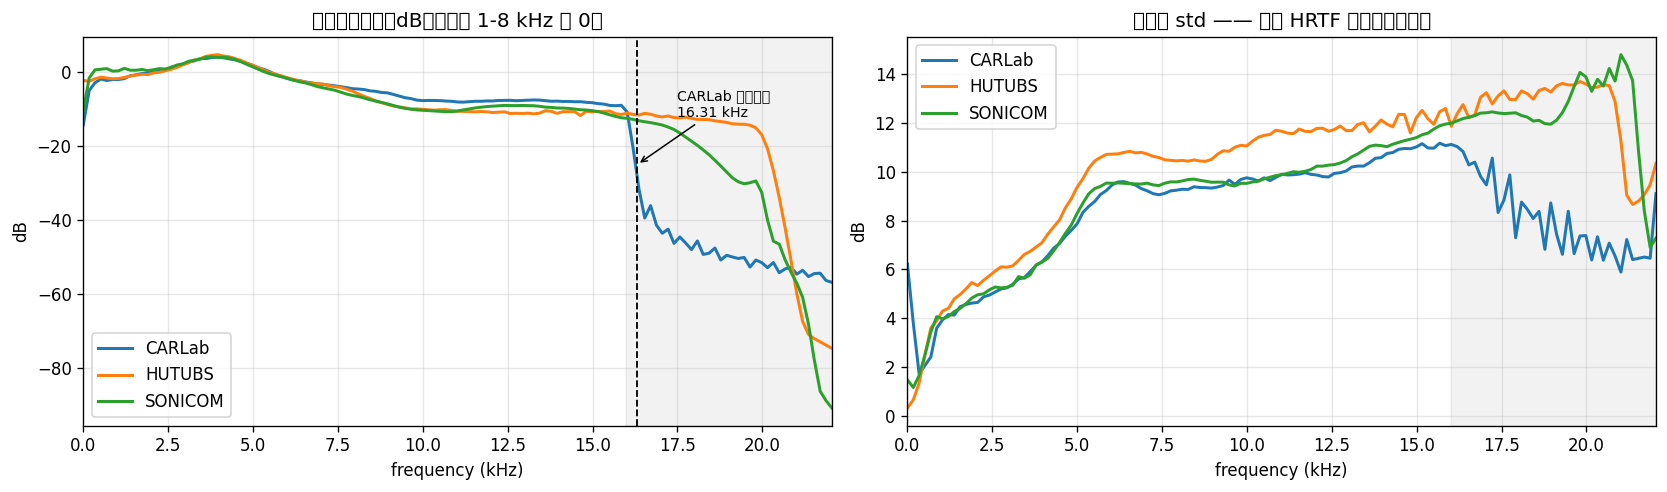

How to read these two plots:
  - The CARLab cliff must sit on the dashed line. If it does not -> the CARLab axis is wrong.
  - If the other two curves are stretched or compressed horizontally against CARLab, the sample rates disagree.
  - A database whose std collapses inside the grey region carries no real information there — this confirms the 16 kHz ceiling.
  - Vertical shifts in the left plot are level / equalisation conventions. That is exactly what FiLM absorbs.

frequency ceiling 16000 Hz -> keep bins 0..92 (93/129), actual fmax 15848 Hz


In [ ]:
# ==========================================================================
# Cell 1 — frequency-axis consistency check
#
# A database without meta.json cannot have its sample rate verified, so this version does:
#   hard check   shape (129, 3072) — this one must hold
#   soft check   meta.json; only a warning if absent
#   evidence     plot the three mean spectra on the SAME physical frequency axis (all 129 bins, to 22.05 kHz).
#                An 8% sample-rate error stretches the spectrum horizontally, most visibly at the top.
#                CARLab has a known landmark: the digital-filter cliff at 16.31 kHz
#                (confirmed by analysis/band_limit_audit.py) — if it lands in the right place the
#                CARLab axis is correct, and the other two aligning with it is then credible.
# ==========================================================================
import os, json
import numpy as np
import matplotlib.pyplot as plt

EXPECT_FS, EXPECT_NFFT, EXPECT_BINS, EXPECT_NPIX = 44100, 256, 129, 3072
DF_FULL = EXPECT_FS / EXPECT_NFFT
F_FULL = np.arange(EXPECT_BINS) * DF_FULL

print(f'assumed: fs={EXPECT_FS} Hz, nfft={EXPECT_NFFT}, {EXPECT_BINS} bins, '
      f'df={DF_FULL:.3f} Hz, fmax={F_FULL[-1]:.0f} Hz')
print('=' * 86)

no_meta, curves = [], {}
for d in DATASETS:
    for side in ('left', 'right'):
        p = d[side]
        mp = os.path.join(p, 'meta.json')
        m = json.load(open(mp)) if os.path.exists(mp) else {}
        if not m and side == 'left':
            no_meta.append(d['tag'])
        files = sorted(f for f in os.listdir(p) if f.endswith('.npy'))
        x = np.load(os.path.join(p, files[0]))
        assert x.shape == (EXPECT_BINS, EXPECT_NPIX), (
            f"{d['tag']}-{side}: shape {x.shape}, expected ({EXPECT_BINS}, {EXPECT_NPIX})")
        tag_meta = (f"fs={m.get('sample_rate')} nfft={m.get('nfft')}"
                    if m else '(no meta.json, sample rate unverified)')
        print(f"  {d['tag']+'-'+side:<16}{len(files):>5} files | shape {x.shape} OK | {tag_meta}")
        if m and (m.get('sample_rate') != EXPECT_FS or m.get('nfft') != EXPECT_NFFT):
            raise AssertionError(f"{d['tag']}-{side} meta does not match the target: {m}")

    # a few subjects: mean spectrum and across-direction std (all 129 bins)
    fl = sorted(f for f in os.listdir(d['left']) if f.endswith('.npy'))[:24]
    A = np.stack([np.load(os.path.join(d['left'], f)) for f in fl])   # (n,129,3072)
    ref = A[:, (F_FULL >= 1000) & (F_FULL <= 8000), :].mean()
    curves[d['tag']] = (A.mean(axis=(0, 2)) - ref, A.std(axis=2).mean(0), ref)
    del A

print('=' * 86)
if no_meta:
    print(f'⚠️ no meta.json: {no_meta} — verify the sample rate from the plot below')

# ---------------- level in the key bands (these differences are what FiLM absorbs) ----------------
print(f"\nMean level per database, dB relative to its own 1-8 kHz (compare shapes across rows; the vertical offsets are absorbed by FiLM)")
BANDS = [(200, 500), (500, 2000), (2000, 6000), (6000, 12000), (12000, 16000),
         (16000, 18000), (18000, 22050)]
print(f"  {'DB':<9}" + ''.join(f'{lo/1000:g}-{hi/1000:g}k'.rjust(9) for lo, hi in BANDS)
      + f"{'1-8k abs':>11}")
for t, (m_, s_, ref) in curves.items():
    row = ''.join(f'{m_[(F_FULL>=lo)&(F_FULL<hi)].mean():>9.1f}' for lo, hi in BANDS)
    print(f'  {t:<9}{row}{ref:>11.1f}')

# ---------------- figure: spectral alignment ----------------
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), dpi=120)
for t, (m_, s_, _) in curves.items():
    ax[0].plot(F_FULL / 1000, m_, lw=1.8, label=t)
    ax[1].plot(F_FULL / 1000, s_, lw=1.8, label=t)
ax[0].axvline(16.3125, color='k', ls='--', lw=1.1)
ax[0].annotate('CARLab known cliff\n16.31 kHz', xy=(16.3125, -25), xytext=(17.5, -12),
               fontsize=8.5, arrowprops=dict(arrowstyle='->', lw=.9))
ax[0].set_title('direction-averaged magnitude (dB, each referenced to its own 1-8 kHz)')
ax[0].set_ylabel('dB')
ax[1].set_title('across-direction std — where the real HRTF information is')
ax[1].set_ylabel('dB')
for a in ax:
    a.axvspan(16, 22.05, color='gray', alpha=.10)
    a.set_xlabel('frequency (kHz)'); a.set_xlim(0, 22.05)
    a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

print('How to read these two plots:')
print('  - The CARLab cliff must sit on the dashed line. If it does not -> the CARLab axis is wrong.')
print('  - If the other two curves are stretched or compressed horizontally against CARLab, the sample rates disagree.')
print('  - A database whose std collapses inside the grey region carries no real information there — this confirms the 16 kHz ceiling.')
print('  - Vertical shifts in the left plot are level / equalisation conventions. That is exactly what FiLM absorbs.')

# ---------------- frequency ceiling ----------------
# Take the lowest ceiling across databases. CARLab is cut by a digital filter at 16.31 kHz, hence 16 kHz.
FREQ_CAP_HZ = 16000
DF = DF_FULL
N_BINS = int(np.floor(FREQ_CAP_HZ / DF)) + 1
print(f'\nfrequency ceiling {FREQ_CAP_HZ} Hz -> keep bins 0..{N_BINS-1} ({N_BINS}/{EXPECT_BINS}), '
      f'actual fmax {(N_BINS-1)*DF:.0f} Hz')


In [ ]:
# ==========================================================================
# Cell 2 — model definition (GELU + FiLM)
# ==========================================================================
import numpy as np
import torch
import torch.nn as nn
import healpy as hp


# ---------------------------------------------- spherical convolution
class OSLOConv(nn.Module):
    """Anisotropic convolution on HEALPix: each pixel plus its 8 neighbours, 9 independent weights."""
    def __init__(self, in_channels, out_channels, nside=16):
        super().__init__()
        self.npix = hp.nside2npix(nside)
        neighbors = hp.get_all_neighbours(nside, np.arange(self.npix))
        rf = np.concatenate([neighbors, np.arange(self.npix)[np.newaxis, :]], axis=0)
        rf[rf == -1] = self.npix
        self.register_buffer('neighborhood', torch.tensor(rf, dtype=torch.int64))
        self.weight = nn.Parameter(torch.empty(out_channels, in_channels, 9))
        self.bias = nn.Parameter(torch.empty(out_channels))
        nn.init.kaiming_uniform_(self.weight, a=np.sqrt(5))
        nn.init.zeros_(self.bias)

    def forward(self, x):
        B, C, _ = x.shape
        pad = torch.zeros(B, C, 1, device=x.device, dtype=x.dtype)
        g = torch.cat([x, pad], dim=2)[:, :, self.neighborhood]
        return torch.einsum('bcqn,ocq->bon', g, self.weight) + self.bias.view(1, -1, 1)


class OSLOResBlock(nn.Module):
    """Frequency-isolated residual block, operating on (B*F, C, N).
    * v2: ReLU -> GELU. HRTF log-magnitude is bipolar (negative means attenuation), so
      ReLU truncates the negative half; GELU is smooth, keeps negatives, and matches the fc layers."""
    def __init__(self, in_channels, out_channels, nside=16, num_groups=8):
        super().__init__()
        self.shortcut = (nn.Conv1d(in_channels, out_channels, 1)
                         if in_channels != out_channels else nn.Identity())
        self.conv1 = OSLOConv(in_channels, out_channels, nside)
        self.gn1 = nn.GroupNorm(num_groups, out_channels)
        self.conv2 = OSLOConv(out_channels, out_channels, nside)
        self.gn2 = nn.GroupNorm(num_groups, out_channels)
        self.act = nn.GELU()

    def forward(self, x):
        res = self.shortcut(x)
        out = self.act(self.gn1(self.conv1(x)))
        out = self.gn2(self.conv2(out))
        return self.act(out + res)


# ---------------------------------------------- per-dataset FiLM
class DatasetFiLM(nn.Module):
    """Learn one PER-FREQUENCY scale/shift curve for each dataset.

    ** Constraint 1: frequency only, NEVER direction.
      A per-frequency affine map is one EQ curve (93 dof per dataset). All it can absorb is
      "colouration common to the whole dataset and independent of direction" — loudspeaker and
      microphone response, equalisation convention, overall level. By construction it CANNOT
      express a direction-dependent difference, so population anatomy (ear-size distributions
      differ across databases) must still live in z. Contrast: subtracting a per-database mean
      over (frequency x direction) is 3072x93 dof, enough to remove the real population structure
      as well — exactly the wrong direction Craig pointed at. A factor of 3072 in expressive power.

    ** Constraint 2: centre across datasets.
      Without centring, log_gamma/beta learn a global EQ that cancels against the network's own
      output gain — a redundant degree of freedom. After the cross-database mean is removed FiLM
      expresses only RELATIVE differences; the absolute part stays in the network. Exactly the identity when num_datasets=1.
    """
    def __init__(self, num_datasets, num_bins):
        super().__init__()
        self.num_datasets = num_datasets
        self.log_gamma = nn.Parameter(torch.zeros(num_datasets, num_bins))
        self.beta = nn.Parameter(torch.zeros(num_datasets, num_bins))

    def params(self, dataset_id):
        lg = self.log_gamma - self.log_gamma.mean(0, keepdim=True)
        bt = self.beta - self.beta.mean(0, keepdim=True)
        return torch.exp(lg[dataset_id]).unsqueeze(-1), bt[dataset_id].unsqueeze(-1)

    def forward(self, x, dataset_id):
        g, b = self.params(dataset_id)
        return x * g + b

    def inverse(self, x, dataset_id):
        g, b = self.params(dataset_id)
        return (x - b) / g


# ---------------------------------------------- encoder / decoder

class Isolated_OSLO_Encoder(nn.Module):
    """Encode each frequency bin independently -> latent (B, F, latent_dim)"""
    def __init__(self, nside=16, latent_dim_per_freq=64):
        super().__init__()
        self.npix = hp.nside2npix(nside)
        self.latent_dim = latent_dim_per_freq
        self.enc1 = OSLOResBlock(1, 16, nside)
        self.enc2 = OSLOResBlock(16, 32, nside)
        self.fc_encode = nn.Sequential(
            nn.Flatten(), nn.Linear(32 * self.npix, 512), nn.GELU(),
            nn.Linear(512, self.latent_dim))

    def forward(self, x):
        B, F, N = x.shape
        z = self.fc_encode(self.enc2(self.enc1(x.reshape(B * F, 1, N))))
        return z.reshape(B, F, self.latent_dim)


class Conditioned_OSLO_Decoder(nn.Module):
    """FFM frequency-conditioned decoder + per-dataset FiLM on the output"""
    def __init__(self, nside=16, latent_dim_per_freq=64, freq_embed_dim=32,
                 num_datasets=1, num_bins=93):
        super().__init__()
        self.npix = hp.nside2npix(nside)
        self.latent_dim = latent_dim_per_freq
        self.freq_embed_dim = freq_embed_dim
        self.ffm_B = nn.Parameter(torch.randn(freq_embed_dim // 2))
        self.fc_decode = nn.Sequential(
            nn.Linear(self.latent_dim + freq_embed_dim, 512), nn.GELU(),
            nn.Linear(512, 32 * self.npix))
        self.dec1 = OSLOResBlock(32, 16, nside)
        self.dec_final = OSLOConv(16, 1, nside)
        self.film = DatasetFiLM(num_datasets, num_bins)

    def get_freq_embedding(self, num_freqs, device):
        f = torch.arange(num_freqs, device=device).float() / (num_freqs - 1)
        proj = 2 * np.pi * f.unsqueeze(1) * self.ffm_B.unsqueeze(0)
        return torch.cat([torch.sin(proj), torch.cos(proj)], dim=1)

    def forward(self, z, dataset_id=None):
        B, F, _ = z.shape
        fe = self.get_freq_embedding(F, z.device).unsqueeze(0).expand(B, -1, -1)
        h = torch.cat([z, fe], dim=-1).reshape(B * F, -1)
        h = self.fc_decode(h).reshape(B * F, 32, self.npix)
        out = self.dec_final(self.dec1(h)).reshape(B, F, self.npix)
        if dataset_id is not None:
            out = self.film(out, dataset_id)
        return out


class FFM_OSLO_Autoencoder(nn.Module):
    """One SHARED-parameter inverse FiLM at the encoder input — zero extra parameters.

    With FiLM on the decoder output only, the colouration stays in x, the encoder takes it in, and it
    lands in z — but z is exactly what the downstream geometry->latent stage needs. Output-side FiLM
    only makes the reconstruction loss line up; it does not clean z.

    Here     x_norm = (x - beta)/gamma        <- remove colouration
             z      = encoder(x_norm)
             out    = gamma * decoder(z) + beta   <- back to the original space, loss still on raw

    The SAME FiLM parameters are used. Together with centring this also kills the trivial degenerate
    direction "scale gamma up, scale the network down". Set tie_encoder_film=False to disable.
    """
    def __init__(self, nside=16, latent_dim_per_freq=64, freq_embed_dim=32,
                 num_datasets=1, num_bins=93, tie_encoder_film=True):
        super().__init__()
        self.encoder = Isolated_OSLO_Encoder(nside, latent_dim_per_freq)
        self.decoder = Conditioned_OSLO_Decoder(nside, latent_dim_per_freq,
                                                freq_embed_dim, num_datasets, num_bins)
        self.tie_encoder_film = tie_encoder_film

    def forward(self, x, dataset_id=None):
        if dataset_id is not None and self.tie_encoder_film:
            x = self.decoder.film.inverse(x, dataset_id)
        z = self.encoder(x)
        return self.decoder(z, dataset_id), z


print('model defined (FFM + FiLM)')

model defined (FFM + FiLM)


In [ ]:
# ==========================================================================
# Cell 3 — config / train-val-test split / losses / model
# (sampling weights live in the next cell and are tuned separately)
# ==========================================================================
import os, json, random, hashlib, time
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, ConcatDataset, WeightedRandomSampler
import healpy as hp

config = {
    'model_type': 'FFM-OSLO-v2.3-MultiDB',
    'nside': 16, 'latent_dim': 64, 'freq_embed_dim': 32,
    'sample_rate': EXPECT_FS, 'num_bins_raw': EXPECT_BINS,
    'freq_cap_hz': FREQ_CAP_HZ,
    'flatten_bins': 0,          # 0 = no flattening, every bin enters the model as-is
    'band_lo_hz': 0,            # 0 = the loss covers the full band
    'num_datasets': len(DATASETS),
    'tie_encoder_film': True,
    'lr': 1e-4, 'batch_size': 8, 'weight_decay': 1e-4,
    'w_mse': 1.0, 'w_spectral': 0.1,
    'amp': True,                # bf16 autocast
    'save_after': 0,            # start writing checkpoints after this epoch (0 = from the first)
    'save_every': 1,            # write 'latest' every N epochs
    'save_optimizer': False,    # 'best' omits Adam moments: 1.2 GB -> 0.4 GB
    'resume_lr_mult': 0.3,      # on resume lr = lr * this; 1.0 = a true warm restart
    'save_dir': '/content/drive/MyDrive/HRTF_Checkpoints',
}
config['num_bins'] = N_BINS
config['band_hi_hz'] = int(round((N_BINS - 1) * DF))
FLAT = config['flatten_bins']

# Low-frequency note (measured on 218 CARLab subjects): bin 0 is DC, 3.26% of pixels < -30 dB,
# lowest -80 dB, variance 1.41x that of bin 20; bin 1 shows 4.0 dB across-direction std where
# physics at ka=0.28 allows only ~1 dB. band_lo_hz=0 puts them in the loss at ~1.5% of total MSE,
# which is acceptable — but the reported numbers are then NOT comparable with the 500 Hz-masked version. Note it in the log.

resume = False               # * adding a database means training from scratch, no warm start
fresh_epochs = 150
additional_epochs = 50

os.makedirs(config['save_dir'], exist_ok=True)
latest_path = os.path.join(config['save_dir'], 'FFM23_latest.pth')
best_path   = os.path.join(config['save_dir'], 'FFM23_best.pth')

# ⚠️ Keep the split filename from the single-database run. build_split is incremental: the CARLab
#    split is unchanged subject by subject, HUTUBS/SONICOM are only appended. That is what makes
#    "single-database vs three-database on the same CARLab val/test" a valid comparison.
split_path = os.path.join(config['save_dir'], 'split_v21.json')

seed = 4
torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU',
      '| TF32:', torch.backends.cuda.matmul.allow_tf32,
      '| AMP bf16:', config['amp'])

# ------------------------------ mirror permutation ------------------------------
if os.path.exists(MIRROR_SRC):
    MIRROR = np.load(MIRROR_SRC)
else:
    npix = hp.nside2npix(config['nside'])
    th, ph = hp.pix2ang(config['nside'], np.arange(npix))
    MIRROR = hp.ang2pix(config['nside'], th, (-ph) % (2 * np.pi))
assert len(np.unique(MIRROR)) == len(MIRROR), 'mirror is not a bijection'
assert np.array_equal(MIRROR[MIRROR], np.arange(len(MIRROR))), 'mirror is not an involution'
print('mirror permutation OK (exact bijection and involution)')


# ------------------------------ monaural dataset ------------------------------
class MonauralHRTFDataset(Dataset):
    """One sample = one ear. Right ears are mirrored across the median plane so every sample lives
    in a left-ear frame. The v1 variance decomposition showed 71.7% of latent variance encoding side — a bit already known."""
    def __init__(self, d, subject_ids_, mirror):
        self.items, self.mirror, self.dataset_id = [], mirror, d['id']
        sl, sr = d['suffix']
        for sid in sorted(subject_ids_):
            for side, sfx, root in (('left', sl, d['left']), ('right', sr, d['right'])):
                p = os.path.join(root, f'{sid}{sfx}')
                if os.path.exists(p):
                    self.items.append((sid, side, p))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        sid, side, path = self.items[i]
        x = np.load(path).astype(np.float32)[:N_BINS]
        if FLAT:
            x[:FLAT] = x[FLAT]
        if side == 'right':
            x = x[:, self.mirror]
        return torch.from_numpy(x), torch.tensor(self.dataset_id), f'{sid}_{side}'


def subject_ids(d):
    sfx = d['suffix'][0]
    return sorted({f[:-len(sfx)] for f in os.listdir(d['left']) if f.endswith(sfx)})


# --------------------- train / val / test: split BY SUBJECT ---------------------
# By subject, not by sample: one person's two ears correlate at 0.978 after mirroring, so a per-sample split leaks.
# Each database is split separately: a small database has a real chance of landing entirely on one side.
# Each uses its own rng (seed + id): adding a database leaves every existing split byte-identical.
# Frozen to disk with a hash of the subject list: the seed is only reproducible while the data is unchanged.
def build_split(datasets, seed, path):
    sp = json.load(open(path)) if os.path.exists(path) else {}
    changed = False
    for d in datasets:
        ids = subject_ids(d)
        h = hashlib.md5(','.join(ids).encode()).hexdigest()[:12]
        if d['tag'] in sp:
            if sp[d['tag']]['hash'] != h:
                raise RuntimeError(
                    f"{d['tag']} subject list changed (stored {sp[d['tag']]['hash']} vs now {h}). "
                    'Re-splitting would contaminate the test set — confirm this is intended first.')
            print(f"  reusing the frozen split for {d['tag']}")
            continue
        rng = np.random.default_rng(seed + d['id'])
        perm = list(ids); rng.shuffle(perm)
        ftr, fva, _ = d['split']
        n = len(perm); n_tr = int(round(ftr * n)); n_va = int(round(fva * n))
        sp[d['tag']] = {'train': perm[:n_tr], 'val': perm[n_tr:n_tr + n_va],
                        'test': perm[n_tr + n_va:], 'n_total': n, 'hash': h}
        changed = True
        print(f"  * new split for {d['tag']} (existing databases unaffected)")
    if changed:
        json.dump(sp, open(path, 'w'), indent=1)
        print(f'  written back to {path}')
    return sp


print(f'\nsplit <- {split_path}')
SPLIT = build_split(DATASETS, seed, split_path)

tr_parts, va_parts, te_parts, rows = [], [], [], []
for d in DATASETS:
    s = SPLIT[d['tag']]
    tr_parts.append(MonauralHRTFDataset(d, s['train'], MIRROR))
    va_parts.append(MonauralHRTFDataset(d, s['val'],   MIRROR))
    te_parts.append(MonauralHRTFDataset(d, s['test'],  MIRROR))
    rows.append((d['id'], d['tag'], s['n_total'], len(s['train']), len(s['val']),
                 len(s['test']), len(tr_parts[-1]), len(va_parts[-1]), len(te_parts[-1])))

train_dataset = ConcatDataset(tr_parts)
val_dataset   = ConcatDataset(va_parts)
test_dataset  = ConcatDataset(te_parts)

print(f"\n{'id':>3} {'DB':<9}{'subj':>6}{'train':>7}{'val':>5}{'test':>6}"
      f"{'tr ear':>7}{'va ear':>6}{'te ear':>6}")
for r in rows:
    print(f'{r[0]:>3} {r[1]:<9}{r[2]:>6}{r[3]:>7}{r[4]:>5}{r[5]:>6}{r[6]:>7}{r[7]:>6}{r[8]:>6}')
print(f'    total  train {len(train_dataset)} ears | val {len(val_dataset)} ears | '
      f'test {len(test_dataset)} ears (do not touch test before the last cell)')

val_loader  = DataLoader(val_dataset,  batch_size=config['batch_size'], shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=config['batch_size'], shuffle=False)


# ------------------------------ band mask ------------------------------
freqs = np.arange(N_BINS) * DF
band = torch.tensor(freqs >= config['band_lo_hz'])
band_dev = band.to(device)
print(f"\nloss band {config['band_lo_hz']}-{config['band_hi_hz']} Hz -> "
      f"{int(band.sum())}/{len(band)} bins"
      + (f' (bins 0..{int((~band).sum())-1} masked)' if (~band).any() else ' (all kept)'))


# ------------------------------ losses ------------------------------
class SpectralGradientLoss(nn.Module):
    """MSE on the first difference along frequency — pushes the model onto the steep notch shapes (band-masked)"""
    def __init__(self, band):
        super().__init__()
        self.register_buffer('m', band[1:] & band[:-1])

    def forward(self, pred, target):
        dp = (pred[:, 1:, :] - pred[:, :-1, :])[:, self.m, :]
        dt = (target[:, 1:, :] - target[:, :-1, :])[:, self.m, :]
        return F.mse_loss(dp, dt)


# ------------------------------ model ------------------------------
model = FFM_OSLO_Autoencoder(
    nside=config['nside'], latent_dim_per_freq=config['latent_dim'],
    freq_embed_dim=config['freq_embed_dim'], num_datasets=config['num_datasets'],
    num_bins=config['num_bins'], tie_encoder_film=config['tie_encoder_film']).to(device)

optimizer = optim.Adam(model.parameters(), lr=config['lr'],
                       weight_decay=config['weight_decay'])
criterion_mse, criterion_mae = nn.MSELoss(), nn.L1Loss()
criterion_spectral = SpectralGradientLoss(band).to(device)

model.eval()
with torch.no_grad():
    dmy = torch.randn(2, N_BINS, 3072).to(device)
    o, z = model(dmy, torch.zeros(2, dtype=torch.long, device=device))
    print(f'\nparams {sum(p.numel() for p in model.parameters())/1e6:.1f} M | '
          f'in {tuple(dmy.shape)} | out {tuple(o.shape)} | latent {tuple(z.shape)}')
    assert o.shape == dmy.shape


# --------------------- * data-driven initialisation of FiLM beta ---------------------
# Absolute levels differ widely (measured 1-8 kHz: CARLab +3.5 / HUTUBS +2.4 / SONICOM -13.3 dB).
# beta is an additive offset in dB, i.e. exactly the gain convention — rather than learning it from 0,
# initialise it to the PER-FREQUENCY cross-database difference measured on the training set.
#
# Why:
#   - from the first step the encoder sees three aligned databases (tie_encoder_film applies x-beta)
#   - the latent never has to encode "which database's level is this" (PROJECT_LOG section 2, action b)
#   - the loss definition is unchanged, so RMSE stays comparable with other runs
#
# gamma stays 0 (gain 1): in dB an overall gain IS an additive offset, already covered by beta; gamma
# would scale the spectral shape, which has no physical motivation — let it learn that on its own.
TAGS = [d['tag'] for d in DATASETS]
with torch.no_grad():
    prof = []
    for tr in tr_parts:
        s = torch.zeros(config['num_bins'])
        for i in range(len(tr)):
            s += tr[i][0].mean(dim=1)                 # (F,) averaged over directions
        prof.append(s / len(tr))
    P = torch.stack(prof)                             # (D, F)
    B0 = P - P.mean(0, keepdim=True)                  # centre across databases
    model.decoder.film.beta.copy_(B0.to(device))

print('\nFiLM beta initialisation (dB, after cross-database centring):')
print(f"  {'DB':<9}{'0.5-2k':>9}{'2-6k':>9}{'6-12k':>9}{'12-16k':>9}{'full band':>10}")
for k, t in enumerate(TAGS):
    r = ''.join(f'{B0[k][(freqs >= lo) & (freqs < hi)].mean():>9.2f}'
                for lo, hi in [(500, 2000), (2000, 6000), (6000, 12000), (12000, 16000)])
    print(f'  {t:<9}{r}{B0[k].mean():>10.2f}')
print('  After training compare with the beta curve drawn in Cell 5: it should look much like this (smooth, EQ-like).')
print('  A notch-shaped structure after training means FiLM has overstepped into population anatomy.')


# ------------------------ mean-HRTF baseline (per database) ------------------------
# One pooled baseline is meaningless: level conventions differ, so the pooled mean is a poor baseline for everyone.
TAGS = [d['tag'] for d in DATASETS]
baselines = {}
with torch.no_grad():
    for d, tr, va in zip(DATASETS, tr_parts, va_parts):
        if len(va) == 0: continue
        mu = torch.stack([tr[i][0] for i in range(len(tr))]).mean(0, keepdim=True)
        V = torch.stack([va[i][0] for i in range(len(va))])
        baselines[d['tag']] = torch.sqrt(((V - mu)[:, band, :] ** 2).mean()).item()
        del V
print(f"\nmean-HRTF baseline ({config['band_lo_hz']}-{config['band_hi_hz']} Hz, each database's own mean):")
for k, v in baselines.items():
    print(f'    {k:<9}{v:.3f} dB')
print('  (the CARLab-only run gave 5.053 dB — the split is unchanged, so this should match)')


def evaluate(loader):
    """returns (pooled RMSE, pooled MAE, {database: RMSE})"""
    model.eval()
    se = torch.zeros(len(TAGS), device=device); ae = torch.zeros(len(TAGS), device=device)
    cnt = torch.zeros(len(TAGS), device=device)
    with torch.no_grad():
        for x, did, _ in loader:
            x, did = x.to(device), did.to(device)
            rec, _ = model(x, did)
            dd = (rec - x)[:, band_dev, :]
            npt = dd[0].numel()
            for k in range(len(TAGS)):
                m = did == k
                if m.any():
                    se[k] += (dd[m] ** 2).sum(); ae[k] += dd[m].abs().sum()
                    cnt[k] += m.sum() * npt
    per = {t: (se[k] / cnt[k]).sqrt().item() if cnt[k] > 0 else float('nan')
           for k, t in enumerate(TAGS)}
    return (se.sum() / cnt.sum()).sqrt().item(), (ae.sum() / cnt.sum()).item(), per

GPU: NVIDIA A100-SXM4-40GB | TF32: True | AMP bf16: True
mirror permutation OK (exact bijection and involution)

split <- /content/drive/MyDrive/HRTF_Checkpoints/split_v21.json
  reusing the frozen split for CARLab
  reusing the frozen split for HUTUBS
  reusing the frozen split for SONICOM

 id DB          subj  train  val  test  tr ear va ear te ear
  0 CARLab      218    174   22    22    348    44    44
  1 HUTUBS       96     58   14    24    116    28    48
  2 SONICOM     399    299   40    60    598    80   120
    total  train 1062 ears | val 152 ears | test 212 ears (do not touch test before the last cell)

loss band 0-15848 Hz -> 93/93 bins (all kept)

params 100.9 M | in (2, 93, 3072) | out (2, 93, 3072) | latent (2, 93, 64)

FiLM beta initialisation (dB, after cross-database centring):
  DB          0.5-2k     2-6k    6-12k   12-16k  full band
  CARLab        5.85     6.25     7.09     7.26      6.70
  HUTUBS        4.91     5.63     5.05     4.06      5.02
  SONICOM     -

In [ ]:
# ==========================================================================
# Cell 3b — * sampling weights (the only place the mix is tuned)
#
# After a change, re-run THIS CELL ONLY: train_loader is rebuilt, the split and the model are not.
#
#   P(database d) is proportional to WEIGHT[d] * n_d ** TAU      uniform within a database
#
#   TAU = 1   natural proportions (by subject count; large databases drown the small ones)
#   TAU = 0.5 compromise (standard practice in multilingual NMT, equivalent to temperature T=2)
#   TAU = 0   fully balanced (small databases repeat often; a 96-subject database overfits easily)
#   WEIGHT    manual weighting on top of TAU; all ones = pure temperature sampling
#
# ⚠️ WEIGHT is not the place to express "this database has a denser grid". After STPS projection onto
#    HEALPix nside=16 every subject is 3072 pixels regardless of how many directions were measured
#    (HUTUBS 440 / SONICOM 793 / CARLab 393 alike). A denser grid buys LOWER INTERPOLATION ERROR —
#    which makes it a better TEST set, so cash that in through split in DATASETS, not here.
#
#    WEIGHT should actually be touched when one database's val RMSE clearly lags, or when its FiLM
#    row stays pinned at 0 (Cell 5 plots the FiLM curves).
# ==========================================================================
TAU = 0.5
WEIGHT = {
    'CARLab':  1.0,
    'HUTUBS':  1.0,
    'SONICOM': 1.0,
}

n = np.array([len(p) for p in tr_parts], float)
w = np.array([WEIGHT.get(t, 1.0) for t in TAGS], float)
P = w * n ** TAU
P /= P.sum()

print(f'TAU = {TAU}   WEIGHT = ' + '  '.join(f'{t} {WEIGHT.get(t,1.0):g}' for t in TAGS))
print(f"\n  {'DB':<9}{'train ear':>9}{'natural':>10}{'sampled':>10}{'passes/epoch':>14}")
for t, ni, Pi in zip(TAGS, n, P):
    print(f'  {t:<9}{int(ni):>9}{ni/n.sum():>10.1%}{Pi:>10.1%}{Pi*n.sum()/ni:>13.2f}x')

print(f"\n  TAU sweep (WEIGHT held at its current value)")
print(f"  {'tau':>5}" + ''.join(f'{t:>10}' for t in TAGS))
for tau_ in (1.0, 0.7, 0.5, 0.3, 0.0):
    q = w * n ** tau_; q /= q.sum()
    print(f'  {tau_:>5.1f}' + ''.join(f'{v:>10.1%}' for v in q))

if len(DATASETS) > 1 and not (TAU == 1.0 and all(v == 1.0 for v in w)):
    per_sample = np.concatenate([np.full(int(ni), Pi / ni) for ni, Pi in zip(n, P)])
    train_loader = DataLoader(
        train_dataset, batch_size=config['batch_size'],
        sampler=WeightedRandomSampler(torch.as_tensor(per_sample, dtype=torch.double),
                                      num_samples=int(n.sum()), replacement=True))
    print('\n-> weighted sampling enabled')
else:
    g = torch.Generator(); g.manual_seed(seed)
    train_loader = DataLoader(train_dataset, batch_size=config['batch_size'],
                              shuffle=True, generator=g)
    print('\n-> natural proportions, plain shuffle')

config['tau'] = TAU
config['weight'] = dict(WEIGHT)
print(f'  one epoch = {int(n.sum())} samples / '
      f'{int(np.ceil(n.sum()/config["batch_size"]))} batches')

TAU = 0.5   WEIGHT = CARLab 1  HUTUBS 1  SONICOM 1

  DB        train ear   natural   sampled  passes/epoch
  CARLab         348     32.8%     34.6%         1.06x
  HUTUBS         116     10.9%     20.0%         1.83x
  SONICOM        598     56.3%     45.4%         0.81x

  TAU sweep (WEIGHT held at its current value)
    tau    CARLab    HUTUBS   SONICOM
    1.0     32.8%     10.9%     56.3%
    0.7     34.2%     15.8%     50.0%
    0.5     34.6%     20.0%     45.4%
    0.3     34.5%     24.8%     40.6%
    0.0     33.3%     33.3%     33.3%

-> weighted sampling enabled
  one epoch = 1062 samples / 133 batches


In [ ]:
import time, torch
sync = lambda: torch.cuda.synchronize() if torch.cuda.is_available() else None

# (1) DataLoader only, GPU untouched
t = time.time()
for i, (x, did, _) in enumerate(train_loader):
    if i == 19: break
t_data = (time.time() - t) / 20

# (2) data already resident on the GPU, timing forward+backward only
xb, db = x.to(device), did.to(device)
for _ in range(3):                                     # warmup
    with torch.autocast('cuda', dtype=torch.bfloat16, enabled=config['amp']):
        r, _ = model(xb, db)
        l = criterion_mse(r[:, band_dev, :], xb[:, band_dev, :])
    l.backward(); optimizer.zero_grad()
sync(); t = time.time()
for _ in range(10):
    with torch.autocast('cuda', dtype=torch.bfloat16, enabled=config['amp']):
        r, _ = model(xb, db)
        l = criterion_mse(r[:, band_dev, :], xb[:, band_dev, :])
    l.backward(); optimizer.step(); optimizer.zero_grad()
sync(); t_gpu = (time.time() - t) / 10

print(f'DataLoader {t_data*1000:.0f} ms/batch | GPU fwd+bwd {t_gpu*1000:.0f} ms/batch')
print(f'sum of the two {(t_data+t_gpu)*1000:.0f} ms  vs measured 1180 ms')
print(f'peak memory {torch.cuda.max_memory_allocated()/1e9:.1f} GB / 40 GB')

DataLoader 7 ms/batch | GPU fwd+bwd 1147 ms/batch
sum of the two 1154 ms  vs measured 1180 ms
peak memory 11.6 GB / 40 GB


In [ ]:
# ==========================================================================
# Locate where the 1136 ms goes
#
# Known: DataLoader 8 ms, GPU fwd+bwd 1136 ms, peak memory 12.1 GB / 40 GB.
#        Compute utilisation ~0.2% — the card is not too slow, some kernel is doing something inefficient.
#
# Suspects, in order:
#   1. OSLOConv's gather backward = scatter-add = many atomic adds (the slowest class of operation)
#   2. einsum('bcqn,ocq->bon') may permute a 2.6 GB tensor internally
#   3. two Linear(98304, 512) (ordinary GEMMs, these should be fast)
#
# Whichever row is largest decides whether to change the code or the hardware.
# ==========================================================================
import time
import torch

sync = lambda: torch.cuda.synchronize() if torch.cuda.is_available() else None
AMP = dict(device_type='cuda', dtype=torch.bfloat16,
           enabled=config['amp'] and torch.cuda.is_available())

B, F_, NP = config['batch_size'], config['num_bins'], 3072
BF = B * F_
print(f'B={B}  F={F_}  ->  B*F={BF} rows, {NP} pixels each\n')


def bench(fn, n=10, warm=3):
    for _ in range(warm):
        fn()
    sync(); t = time.time()
    for _ in range(n):
        fn()
    sync(); return (time.time() - t) / n * 1000


# ---------------- the largest OSLOConv: enc2.conv2 (32->32) ----------------
conv = model.encoder.enc2.conv2
xt = torch.randn(BF, 32, NP, device=device, requires_grad=True)
nb = conv.neighborhood
w = conv.weight

def gather_only():
    pad = torch.zeros(BF, 32, 1, device=device, dtype=xt.dtype)
    return torch.cat([xt.detach(), pad], dim=2)[:, :, nb]

g = gather_only().detach()
gb = g.to(torch.bfloat16)

def einsum_only():
    with torch.autocast(**AMP):
        return torch.einsum('bcqn,ocq->bon', g, w)

def matmul_alt():
    """Avoid einsum: view as (b, c*q, n) then matmul directly, dodging a possible permute"""
    with torch.autocast(**AMP):
        return torch.matmul(w.reshape(w.shape[0], -1), g.reshape(BF, 32 * 9, NP))

def conv_fwd():
    with torch.autocast(**AMP):
        return conv(xt)

def conv_fwdbwd():
    with torch.autocast(**AMP):
        y = conv(xt)
    y.float().sum().backward()
    xt.grad = None

lin = model.encoder.fc_encode
h = torch.randn(BF, 32, NP, device=device, requires_grad=True)

def lin_fwd():
    with torch.autocast(**AMP):
        return lin(h)

def lin_fwdbwd():
    with torch.autocast(**AMP):
        y = lin(h)
    y.float().sum().backward()
    h.grad = None

rows = [
    ('gather alone (fwd)',             gather_only),
    ('einsum alone (fwd)',             einsum_only),
    ('matmul instead of einsum (fwd)', matmul_alt),
    ('OSLOConv 32->32 fwd',            conv_fwd),
    ('OSLOConv 32->32 fwd+bwd',        conv_fwdbwd),
    ('fc_encode Linear fwd',           lin_fwd),
    ('fc_encode Linear fwd+bwd',       lin_fwdbwd),
]
print(f"  {'component':<30}{'ms':>9}{'of 1136 ms':>12}")
res = {}
for name, fn in rows:
    try:
        ms = bench(fn)
        res[name] = ms
        print(f'  {name:<30}{ms:>9.1f}{ms/1136:>11.1%}')
    except RuntimeError as e:
        print(f'  {name:<30}   skipped: {str(e)[:44]}')

print(f'\n  gather tensor: {g.numel()*4/1e9:.2f} GB (fp32) / '
      f'{g.numel()*2/1e9:.2f} GB (bf16)')
print(f'  the model has 7 OSLOConv in total, 2 of them at C_in=32')

if 'OSLOConv 32->32 fwd+bwd' in res and 'OSLOConv 32->32 fwd' in res:
    f_, fb = res['OSLOConv 32->32 fwd'], res['OSLOConv 32->32 fwd+bwd']
    print(f'\n  bwd / fwd = {(fb-f_)/f_:.1f}x'
          '   (should be ~2x; far above 2 means the scatter-add atomics are the bottleneck)')
if 'einsum alone (fwd)' in res and 'matmul instead of einsum (fwd)' in res:
    e_, m_ = res['einsum alone (fwd)'], res['matmul instead of einsum (fwd)']
    print(f'  einsum / matmul = {e_/m_:.2f}x'
          f'   (>1.3 means einsum adds an internal permute and is worth replacing)')


B=8  F=93  ->  B*F=744 rows, 3072 pixels each

  component                              ms   of 1136 ms
  gather alone (fwd)                    6.7       0.6%
  einsum alone (fwd)                   12.6       1.1%
  matmul instead of einsum (fwd)       11.5       1.0%
  OSLOConv 32->32 fwd                  17.2       1.5%
  OSLOConv 32->32 fwd+bwd             260.7      22.9%
  fc_encode Linear fwd                  0.9       0.1%
  fc_encode Linear fwd+bwd              2.8       0.2%

  gather tensor: 2.63 GB (fp32) / 1.32 GB (bf16)
  the model has 7 OSLOConv in total, 2 of them at C_in=32

  bwd / fwd = 14.2x   (should be ~2x; far above 2 means the scatter-add atomics are the bottleneck)
  einsum / matmul = 1.09x   (>1.3 means einsum adds an internal permute and is worth replacing)


In [ ]:
# ==========================================================================
# Cell 4 — training (interruptible, resumes towards the target epoch)
#
# Usage: TOTAL_EPOCHS is an ABSOLUTE target, not "how many more".
#   first run          -> trains from 1 to TOTAL_EPOCHS
#   interrupted at 30  -> reconnect, run Cells 0-3 in order, then this cell;
#                         it continues automatically from epoch 31 to TOTAL_EPOCHS
#   already finished   -> raise TOTAL_EPOCHS, or use EXTEND_EPOCHS (below)
#
# * Key point: the learning rate follows the cosine defined over the FULL TOTAL_EPOCHS and does not restart at the interruption.
#   This is done by constructing the scheduler and then stepping it forward done_epochs times.
#   initial_lr must also be written back explicitly — optimizer.load_state_dict restores lr to
#   "the value at the interruption", and without the write-back the scheduler takes that as the cosine start and the whole curve collapses.
#
# * Saving uses a temporary file + os.replace (atomic). If the connection drops halfway through
#   writing 1.2 GB, the original file is not truncated into a corrupt checkpoint.
# ==========================================================================
import os, time
import numpy as np
import torch

TOTAL_EPOCHS  = 100      # <- absolute target epoch count
EXTEND_EPOCHS = 50       # extra epochs to run once TOTAL_EPOCHS has already been reached
RESUME = 'auto'          # 'auto' = resume if a checkpoint exists; True = require one; False = force from scratch

# resume / fresh_epochs / additional_epochs in Cell 3 are unused from this version on


def save_ckpt(obj, path):
    """Write .tmp then replace atomically, so a drop mid-write cannot corrupt the checkpoint"""
    tmp = path + '.tmp'
    torch.save(obj, tmp)
    os.replace(tmp, path)


history = {'train_rmse': [], 'val_rmse': [], 'val_mae': [], 'train_loss_total': [],
           'per_dataset': []}
best_val_rmse, done_epochs = float('inf'), 0

ckpt = None
if RESUME and os.path.exists(latest_path):
    try:
        ckpt = torch.load(latest_path, map_location=device, weights_only=False)
        n_ds, n_bins = ckpt['model_state_dict']['decoder.film.beta'].shape
        if (n_bins, n_ds) != (config['num_bins'], config['num_datasets']):
            raise RuntimeError(
                f"checkpoint has {n_ds} databases / {n_bins} bins, current is {config['num_datasets']} / "
                f"{config['num_bins']} — the configuration changed, cannot continue")
    except Exception as e:
        if RESUME == 'auto':
            print(f'* checkpoint unusable ({type(e).__name__}: {e}), starting from scratch')
            ckpt = None
        else:
            raise
elif RESUME is True:
    raise FileNotFoundError(f'RESUME=True but no checkpoint: {latest_path}')

if ckpt is not None:
    model.load_state_dict(ckpt['model_state_dict'])
    optimizer.load_state_dict(ckpt['optimizer_state_dict'])
    history = ckpt.get('history', history)
    done_epochs = ckpt.get('epoch', -1) + 1
    hv = history.get('val_rmse') or [ckpt.get('val_rmse', float('inf'))]
    best_val_rmse = min(hv)
    best_at = hv.index(best_val_rmse) + 1
    del ckpt
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    if done_epochs < TOTAL_EPOCHS:
        epochs, base_lr, skip = TOTAL_EPOCHS - done_epochs, config['lr'], done_epochs
        T_max, mode = TOTAL_EPOCHS, f'continuing to epoch {TOTAL_EPOCHS} (original cosine, no restart)'
    else:
        epochs, base_lr, skip = EXTEND_EPOCHS, config['lr'] * config['resume_lr_mult'], 0
        T_max = EXTEND_EPOCHS
        mode = (f'already ran {done_epochs} epochs, extending by {EXTEND_EPOCHS}'
                f" (new cosine, start lr = lr x {config['resume_lr_mult']})")
    print(f'resume: {done_epochs} epochs done | best so far {best_val_rmse:.4f} dB '
          f'(epoch {best_at})')
    print(f'      {mode}')
    if len(hv) >= 3:
        print(f'      last three val: ' + '  '.join(f'{v:.4f}' for v in hv[-3:]))
else:
    epochs, base_lr, skip, T_max = TOTAL_EPOCHS, config['lr'], 0, TOTAL_EPOCHS
    print(f'training from scratch for {TOTAL_EPOCHS} epochs')

# * Must be written back explicitly, or the scheduler takes "the lr at the interruption" as the cosine start
for pg in optimizer.param_groups:
    pg['lr'] = pg['initial_lr'] = base_lr
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=T_max, eta_min=1e-6)
for _ in range(skip):                      # step the scheduler forward to the interruption point
    scheduler.step()
print(f'this run: {epochs} epochs | start lr {optimizer.param_groups[0]["lr"]:.3e} '
      f'| T_max {T_max}')

for ep in range(epochs):
    ep_global = done_epochs + ep + 1
    lr_used = optimizer.param_groups[0]['lr']        # the lr actually used this epoch

    # ---------------- train ----------------
    t0 = time.time()
    model.train()
    tot, mse_sum, nb = 0.0, 0.0, 0
    for x, did, _ in train_loader:
        x, did = x.to(device), did.to(device)
        optimizer.zero_grad()
        with torch.autocast('cuda', dtype=torch.bfloat16,
                            enabled=config['amp'] and torch.cuda.is_available()):
            rec, _ = model(x, did)
            loss_mse = criterion_mse(rec[:, band_dev, :], x[:, band_dev, :])
            loss_spe = criterion_spectral(rec, x)
            loss = config['w_mse'] * loss_mse + config['w_spectral'] * loss_spe
        loss.backward(); optimizer.step()
        tot += loss.item(); mse_sum += loss_mse.item(); nb += 1
    scheduler.step()
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t_train = time.time() - t0

    # ---------------- val ----------------
    t1 = time.time()
    va_rmse, va_mae, per = evaluate(val_loader)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t_eval = time.time() - t1

    tr_rmse = (mse_sum / nb) ** .5
    history['train_loss_total'].append(tot / nb)
    history['train_rmse'].append(tr_rmse)
    history['val_rmse'].append(va_rmse)
    history['val_mae'].append(va_mae)
    history['per_dataset'].append(per)

    # ---------------- save ----------------
    t2 = time.time()
    is_best = False
    if ep_global > config['save_after']:
        state = {'epoch': done_epochs + ep, 'model_state_dict': model.state_dict(),
                 'optimizer_state_dict': optimizer.state_dict(), 'history': history,
                 'val_rmse': va_rmse, 'config': config, 'split': SPLIT,
                 'total_epochs': TOTAL_EPOCHS,
                 'datasets': [{k: v for k, v in d.items() if k != 'zips'} for d in DATASETS]}
        if ep_global % config['save_every'] == 0 or ep == epochs - 1:
            save_ckpt(state, latest_path)
        if va_rmse < best_val_rmse:
            best_val_rmse = va_rmse
            is_best = True
            save_ckpt(state if config['save_optimizer'] else
                      {k: v for k, v in state.items() if k != 'optimizer_state_dict'},
                      best_path)
        del state
    t_save = time.time() - t2

    # ---------------- one-line log ----------------
    extra = ('' if len(TAGS) == 1 else
             ' | ' + '  '.join(f'{t} {per[t]:.3f}' for t in TAGS))
    eta = (t_train + t_eval + t_save) * (epochs - ep - 1) / 60
    print(f'Epoch {ep_global:>3}/{done_epochs+epochs} | train {tr_rmse:.4f} | '
          f'val {va_rmse:.4f} dB | MAE {va_mae:.4f}' + extra
          + f' | lr {lr_used:.2e}'
          + f' | {t_train:.0f}/{t_eval:.0f}/{t_save:.0f}s'
          + f' | ETA {eta:.0f}min'
          + ('  ★best' if is_best else ''))

print(f'\nreached epoch {done_epochs + epochs}. Best val RMSE = {best_val_rmse:.4f} dB')
if done_epochs + epochs < TOTAL_EPOCHS:
    print(f'{TOTAL_EPOCHS - done_epochs - epochs} epochs short of the {TOTAL_EPOCHS} target — '
          'just re-run this cell after reconnecting')
for k, v in baselines.items():
    print(f'    mean-HRTF baseline for {k}: {v:.3f} dB')


resume: 64 epochs done | best so far 1.5326 dB (epoch 64)
      continuing to epoch 100 (original cosine, no restart)
      last three val: 1.5360  1.5491  1.5326
this run: 36 epochs | start lr 2.942e-05 | T_max 100


/tmp/ipykernel_12138/924743077.py:92: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


Epoch  65/100 | train 1.4561 | val 1.5293 dB | MAE 0.9627 | CARLab 1.397  HUTUBS 1.837  SONICOM 1.479 | lr 2.94e-05 | 157/4/8s | ETA 99min  ★best
Epoch  66/100 | train 1.4568 | val 1.5293 dB | MAE 0.9648 | CARLab 1.393  HUTUBS 1.835  SONICOM 1.482 | lr 2.80e-05 | 153/2/3s | ETA 89min
Epoch  67/100 | train 1.4593 | val 1.5280 dB | MAE 0.9618 | CARLab 1.393  HUTUBS 1.837  SONICOM 1.479 | lr 2.67e-05 | 153/2/8s | ETA 89min  ★best
Epoch  68/100 | train 1.4349 | val 1.5267 dB | MAE 0.9606 | CARLab 1.391  HUTUBS 1.837  SONICOM 1.478 | lr 2.53e-05 | 153/2/7s | ETA 86min  ★best
Epoch  69/100 | train 1.4425 | val 1.5303 dB | MAE 0.9691 | CARLab 1.396  HUTUBS 1.837  SONICOM 1.482 | lr 2.40e-05 | 153/2/3s | ETA 81min
Epoch  70/100 | train 1.4555 | val 1.5246 dB | MAE 0.9609 | CARLab 1.392  HUTUBS 1.830  SONICOM 1.476 | lr 2.27e-05 | 153/2/8s | ETA 81min  ★best
Epoch  71/100 | train 1.4514 | val 1.5238 dB | MAE 0.9590 | CARLab 1.390  HUTUBS 1.833  SONICOM 1.474 | lr 2.14e-05 | 153/2/8s | ETA 78min

loaded FFM23_best.pth | epoch 99 | val RMSE 1.5042 dB
  CARLab    train  174 / val  22 / test  22 subjects
  HUTUBS    train   58 / val  14 / test  24 subjects
  SONICOM   train  299 / val  40 / test  60 subjects


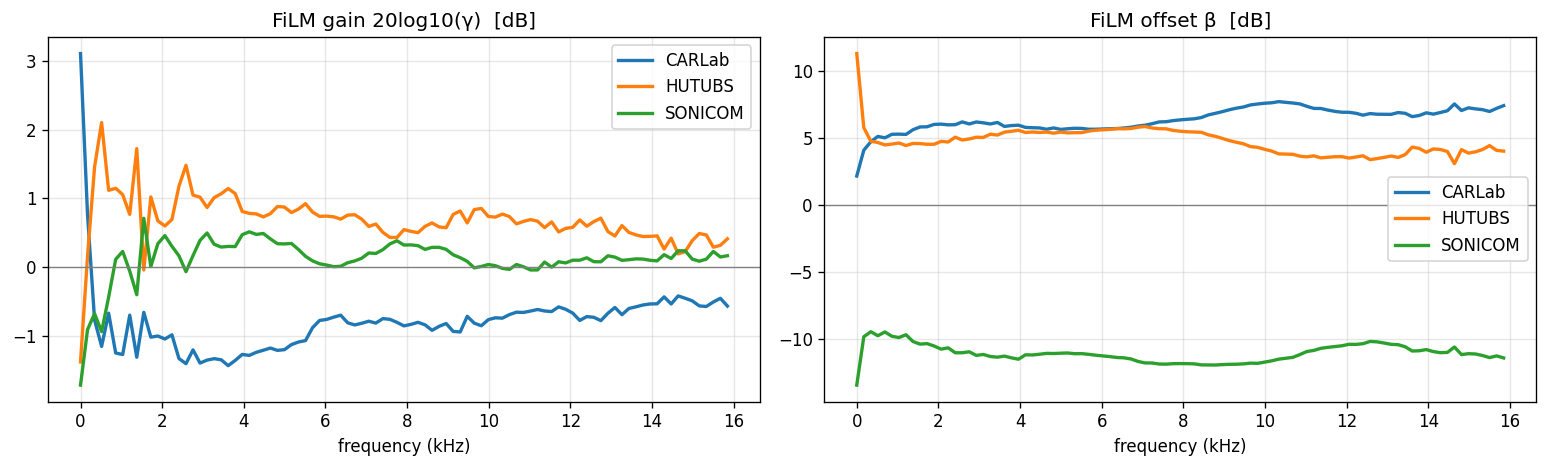

These should look like EQ curves: smooth, broad envelopes.
A notch-shaped structure means FiLM is absorbing the population anatomy that belongs in the latent —
exactly the direction Craig rejected. The paper must be able to show that it did not happen.
  CARLab    peak |gamma|  3.11 dB | peak |beta|  7.73 dB
  HUTUBS    peak |gamma|  2.10 dB | peak |beta| 11.32 dB
  SONICOM   peak |gamma|  1.72 dB | peak |beta| 13.49 dB


In [ ]:
# ==========================================================================
# Cell 5 — load checkpoint (start here for evaluation only, skipping Cell 4)
# ==========================================================================
ckpt = torch.load(best_path, map_location=device, weights_only=False)
n_ds_ck, n_bins_ck = ckpt['model_state_dict']['decoder.film.beta'].shape
assert (n_bins_ck, n_ds_ck) == (config['num_bins'], config['num_datasets']), (
    f"checkpoint has {n_ds_ck} databases / {n_bins_ck} bins, current {config['num_datasets']} / "
    f"{config['num_bins']} — configuration mismatch")
model.load_state_dict(ckpt['model_state_dict'])
model.eval()
history = ckpt.get('history', {})
print(f"loaded {os.path.basename(best_path)} | epoch {ckpt['epoch']+1} | "
      f"val RMSE {ckpt['val_rmse']:.4f} dB")

if 'split' in ckpt:
    SPLIT = ckpt['split']
    va_parts = [MonauralHRTFDataset(d, SPLIT[d['tag']]['val'],  MIRROR) for d in DATASETS]
    te_parts = [MonauralHRTFDataset(d, SPLIT[d['tag']]['test'], MIRROR) for d in DATASETS]
    val_loader  = DataLoader(ConcatDataset(va_parts), batch_size=config['batch_size'], shuffle=False)
    test_loader = DataLoader(ConcatDataset(te_parts), batch_size=config['batch_size'], shuffle=False)
    for d in DATASETS:
        s = SPLIT[d['tag']]
        print(f"  {d['tag']:<9} train {len(s['train']):>4} / val {len(s['val']):>3} / "
              f"test {len(s['test']):>3} subjects")
del ckpt
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# * The measurement colouration each database learned — the most informative plot in multi-database training
if config['num_datasets'] > 1:
    import matplotlib.pyplot as plt
    with torch.no_grad():
        lg = (model.decoder.film.log_gamma
              - model.decoder.film.log_gamma.mean(0, keepdim=True)).cpu().numpy()
        bt = (model.decoder.film.beta
              - model.decoder.film.beta.mean(0, keepdim=True)).cpu().numpy()
    fig, ax = plt.subplots(1, 2, figsize=(13, 4), dpi=120)
    for k, t in enumerate(TAGS):
        ax[0].plot(freqs / 1000, 20 * np.log10(np.exp(lg[k])), lw=2, label=t)
        ax[1].plot(freqs / 1000, bt[k], lw=2, label=t)
    ax[0].set_title('FiLM gain 20log10(γ)  [dB]'); ax[1].set_title('FiLM offset β  [dB]')
    for a in ax:
        a.set_xlabel('frequency (kHz)'); a.axhline(0, color='gray', lw=.8)
        a.legend(); a.grid(alpha=.3)
    plt.tight_layout(); plt.show()
    print('These should look like EQ curves: smooth, broad envelopes.')
    print('A notch-shaped structure means FiLM is absorbing the population anatomy that belongs in the latent —')
    print('exactly the direction Craig rejected. The paper must be able to show that it did not happen.')
    for k, t in enumerate(TAGS):
        print(f'  {t:<9} peak |gamma| {np.abs(20*np.log10(np.exp(lg[k]))).max():5.2f} dB'
              f' | peak |beta| {np.abs(bt[k]).max():5.2f} dB')

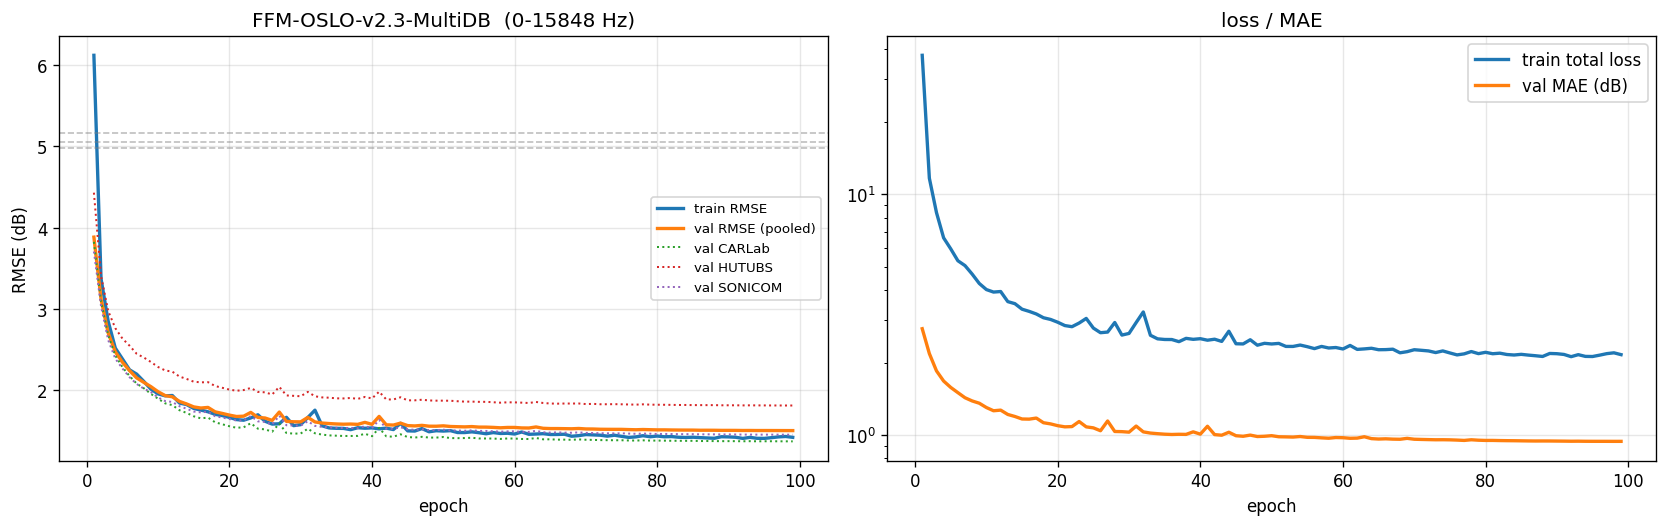

best epoch 99: val RMSE 1.5042 dB
  per database: CARLab 1.372/5.05  HUTUBS 1.813/5.16  SONICOM 1.454/4.98
  format = val/baseline. A database whose ratio is clearly worse than the others -> consider its WEIGHT in Cell 3b


In [ ]:
# ==========================================================================
# Cell 6 — training curves (including per-database)
# ==========================================================================
import matplotlib.pyplot as plt

ep = np.arange(1, len(history['val_rmse']) + 1)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), dpi=120)

ax[0].plot(ep, history['train_rmse'], label='train RMSE', lw=2)
ax[0].plot(ep, history['val_rmse'], label='val RMSE (pooled)', lw=2)
if len(TAGS) > 1 and history.get('per_dataset'):
    for t in TAGS:
        ax[0].plot(ep, [h.get(t, np.nan) for h in history['per_dataset']],
                   lw=1.2, ls=':', label=f'val {t}')
for t, v in baselines.items():
    ax[0].axhline(v, color='gray', ls='--', lw=1, alpha=.5)
ax[0].set_xlabel('epoch'); ax[0].set_ylabel('RMSE (dB)')
ax[0].set_title(f"{config['model_type']}  ({config['band_lo_hz']}-{config['band_hi_hz']} Hz)")
ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)

ax[1].semilogy(ep, history['train_loss_total'], lw=2, label='train total loss')
ax[1].plot(ep, history['val_mae'], lw=2, label='val MAE (dB)')
ax[1].set_xlabel('epoch'); ax[1].legend(); ax[1].grid(alpha=.3); ax[1].set_title('loss / MAE')

plt.tight_layout(); plt.show()

best_ep = int(np.argmin(history['val_rmse'])) + 1
print(f"best epoch {best_ep}: val RMSE {min(history['val_rmse']):.4f} dB")
if history.get('per_dataset'):
    b = history['per_dataset'][best_ep - 1]
    print(f"  per database: " + '  '.join(f'{t} {b.get(t, float("nan")):.3f}'
                                  f'/{baselines.get(t, float("nan")):.2f}' for t in TAGS))
    print('  format = val/baseline. A database whose ratio is clearly worse than the others -> consider its WEIGHT in Cell 3b')

CARLab subject CL010   (22 subjects in val: ['CL010', 'CL029', 'CL054', 'CL056', 'CL075', 'CL085'] ...)


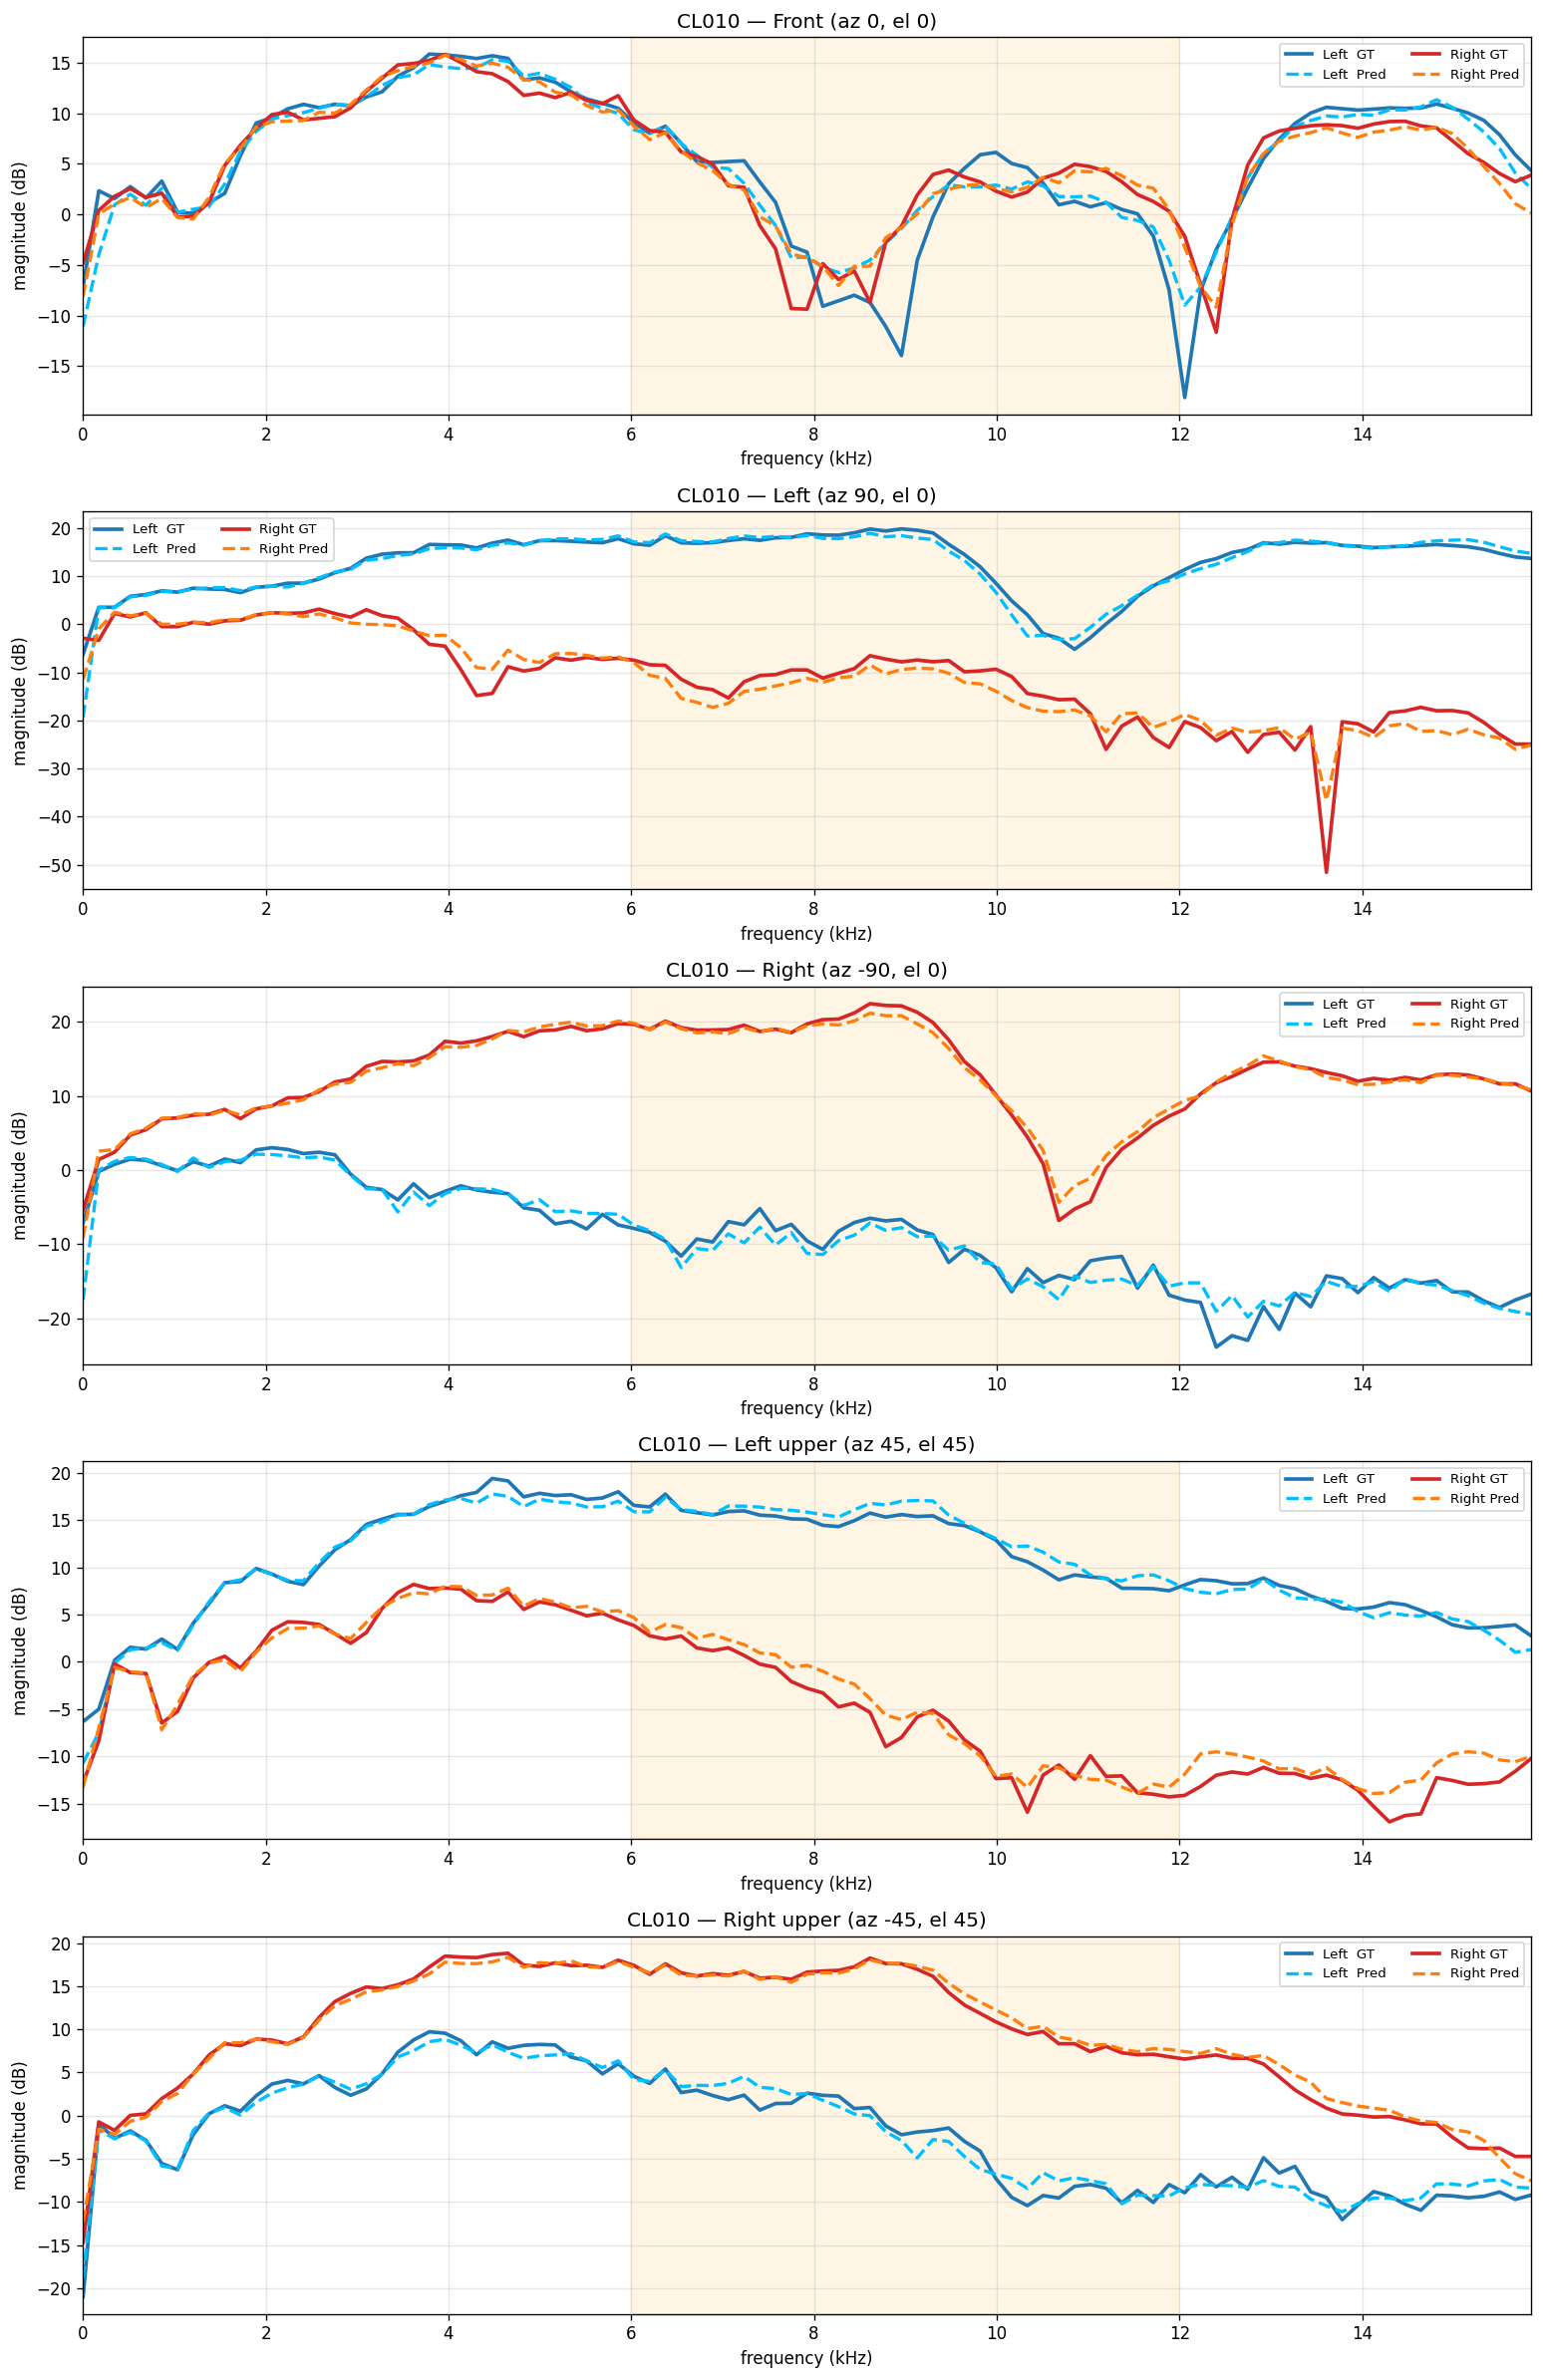

x-axis truncated at 15848 Hz; orange = the 6-12 kHz notch band


In [ ]:
# ==========================================================================
# Cell 7 — spectral reconstruction comparison (5 representative directions, both ears)
# ==========================================================================
import matplotlib.pyplot as plt
import healpy as hp

DB_PICK = 0                                   # change here to look at another database (0/1/2)
part = va_parts[DB_PICK]
DID = DATASETS[DB_PICK]['id']
val_subjects = sorted({it[0] for it in part.items})
TARGET = val_subjects[0]
print(f"{DATASETS[DB_PICK]['tag']} subject {TARGET}   "
      f"({len(val_subjects)} subjects in val: {val_subjects[:6]} ...)")


def predict_ear(sid, side):
    """Returns (gt, pred), both restored to that ear's OWN original frame.
    The model works in a left-ear frame; a right ear is mirrored in, so its output is mirrored back (involution)."""
    for s, sd_, path in part.items:
        if s == sid and sd_ == side:
            x = np.load(path).astype(np.float32)[:N_BINS]
            if FLAT:
                x[:FLAT] = x[FLAT]
            xin = x[:, MIRROR] if side == 'right' else x
            with torch.no_grad():
                p, _ = model(torch.from_numpy(xin)[None].to(device),
                             torch.full((1,), DID, dtype=torch.long, device=device))
            p = p[0].cpu().numpy()
            if side == 'right':
                p = p[:, MIRROR]
            return x, p
    return None, None


gt_l, pred_l = predict_ear(TARGET, 'left')
gt_r, pred_r = predict_ear(TARGET, 'right')

directions = {
    'Front (az 0, el 0)':          (np.pi / 2, 0.0),
    'Left (az 90, el 0)':          (np.pi / 2, np.pi / 2),
    'Right (az -90, el 0)':        (np.pi / 2, -np.pi / 2),
    'Left upper (az 45, el 45)':   (np.pi / 4, np.pi / 4),
    'Right upper (az -45, el 45)': (np.pi / 4, -np.pi / 4),
}
freqs_khz = freqs / 1000.0

fig, axes = plt.subplots(len(directions), 1, figsize=(13, 4 * len(directions)), dpi=120)
for ax, (name, (th, ph)) in zip(axes, directions.items()):
    pix = hp.ang2pix(config['nside'], th, ph)
    ax.plot(freqs_khz, gt_l[:, pix],   color='#1f77b4', lw=2.2, label='Left  GT')
    ax.plot(freqs_khz, pred_l[:, pix], color='#00BFFF', lw=2.0, ls='--', label='Left  Pred')
    if gt_r is not None:
        ax.plot(freqs_khz, gt_r[:, pix],   color='#d62728', lw=2.2, label='Right GT')
        ax.plot(freqs_khz, pred_r[:, pix], color='#ff7f0e', lw=2.0, ls='--', label='Right Pred')
    ax.axvspan(6, 12, color='orange', alpha=.10)
    ax.set_xlim(0, freqs_khz[-1]); ax.set_xlabel('frequency (kHz)')
    ax.set_ylabel('magnitude (dB)'); ax.set_title(f'{TARGET} — {name}')
    ax.legend(fontsize=8, ncol=2); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
print(f"x-axis truncated at {config['band_hi_hz']} Hz; orange = the 6-12 kHz notch band")

/tmp/ipykernel_1719/510362418.py:28: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); plt.show()


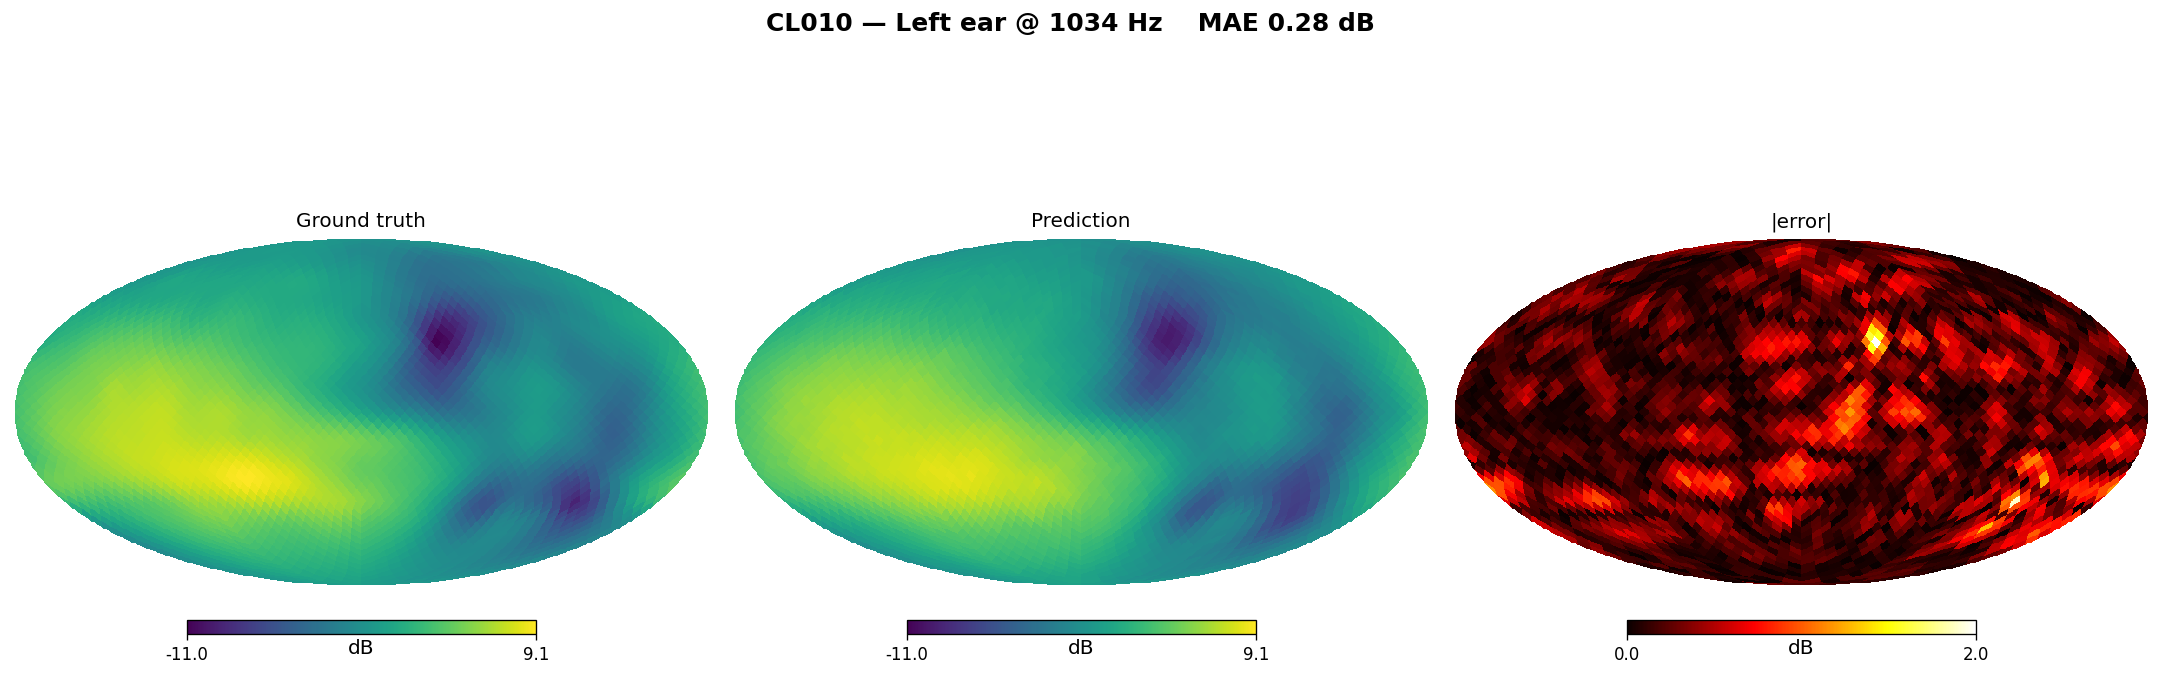

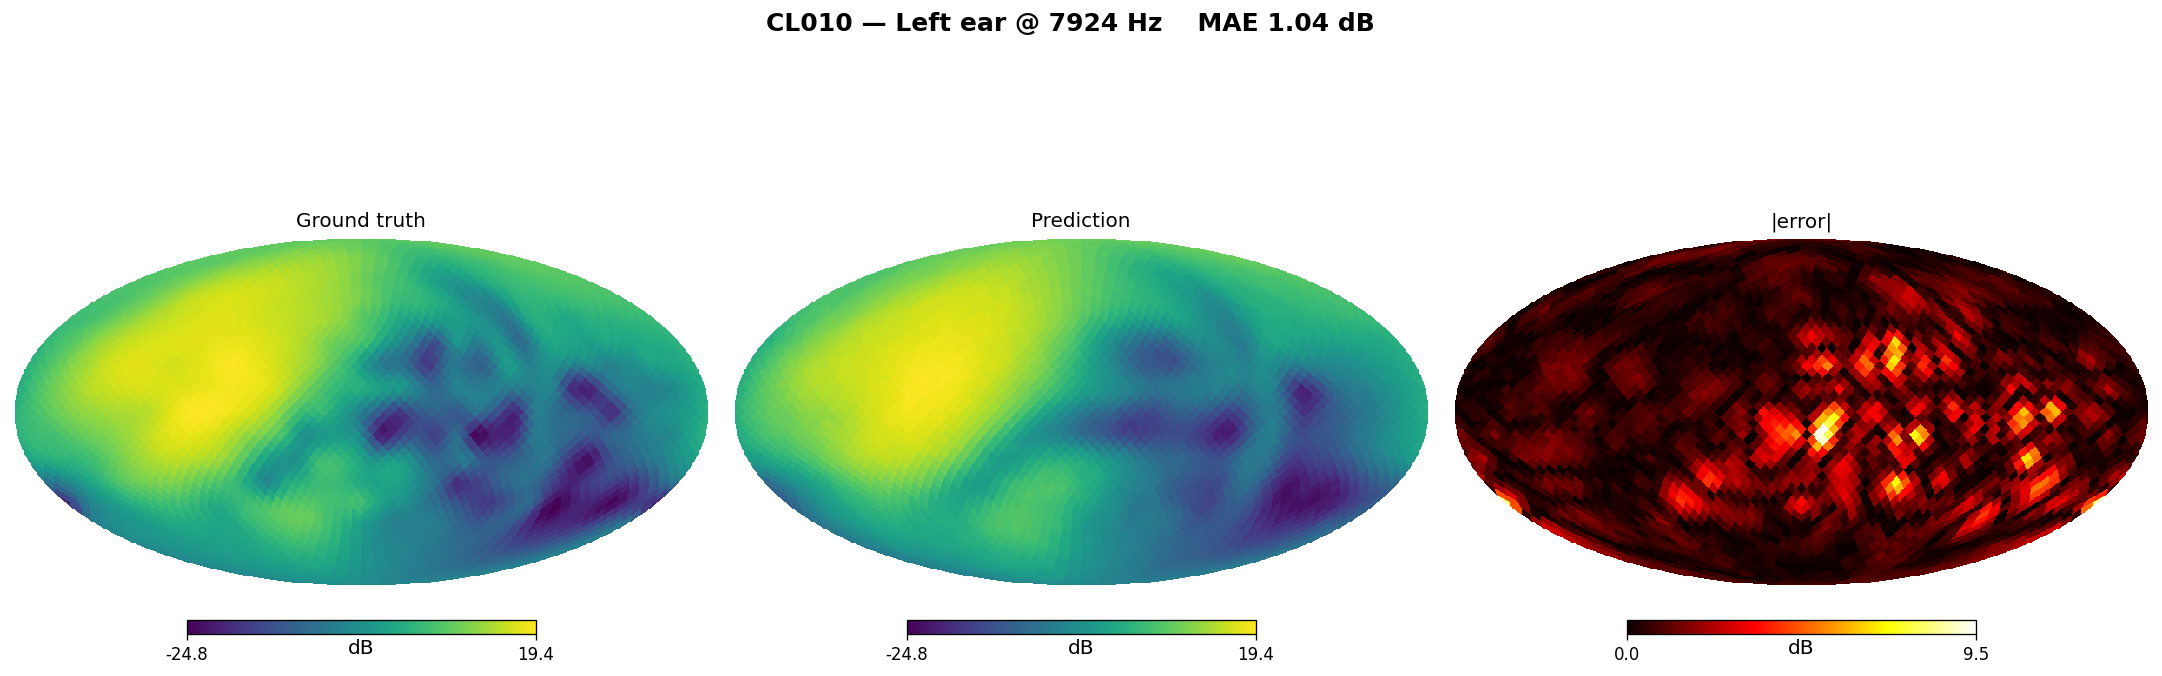

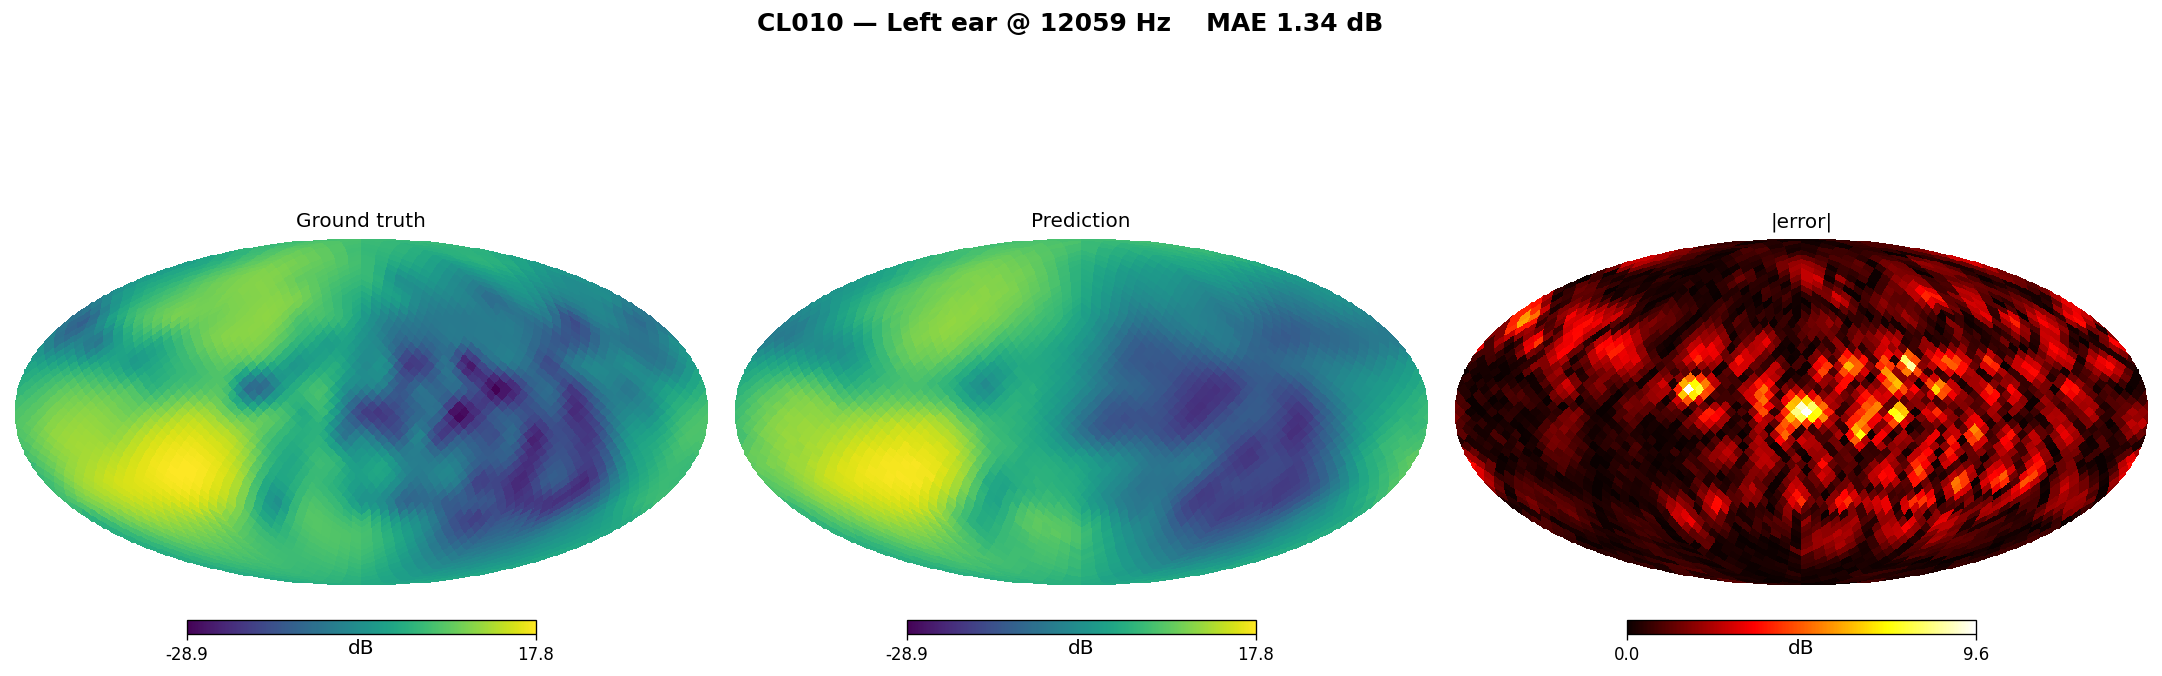

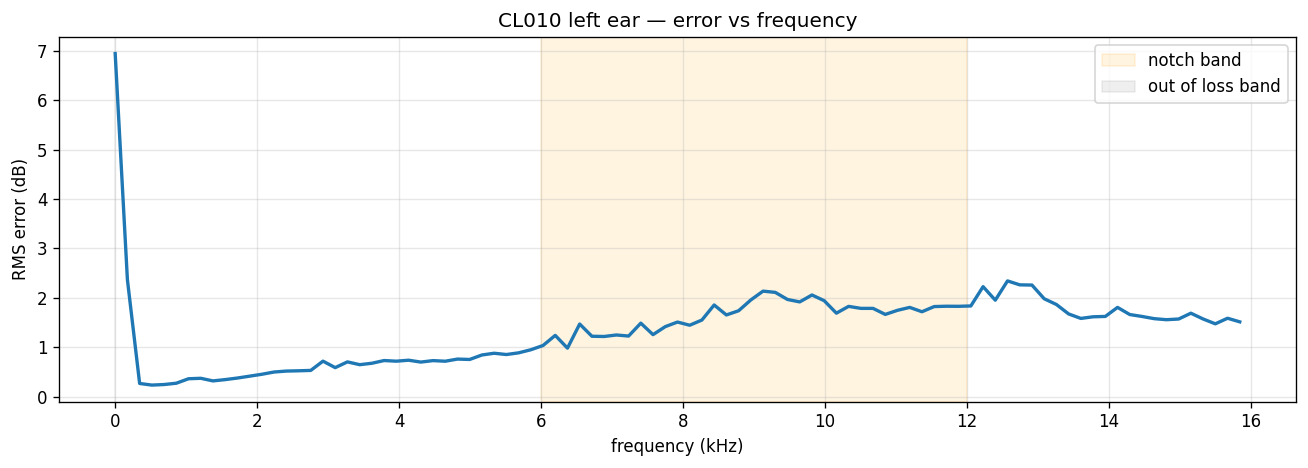

In [ ]:
# ==========================================================================
# Cell 8 — HEALPix spatial maps (GT / Pred / error)
# ==========================================================================
import matplotlib.pyplot as plt
import healpy as hp


def plot_healpix_map(gt, pred, target_hz, subject, ear='Left'):
    # * v1 computed the frequency index as 16000/128, which is wrong: the bin step is fs/256.
    df = config['sample_rate'] / 256.0
    k = int(round(target_hz / df))
    k = min(max(k, 0), config['num_bins'] - 1)
    f_actual = k * df

    g, p = gt[k, :], pred[k, :]
    err = np.abs(g - p)
    vmin, vmax = min(g.min(), p.min()), max(g.max(), p.max())

    fig = plt.figure(figsize=(18, 5.5), dpi=120)
    plt.suptitle(f'{subject} — {ear} ear @ {f_actual:.0f} Hz    MAE {err.mean():.2f} dB',
                 fontsize=15, fontweight='bold', y=1.02)
    hp.mollview(g,   fig=fig.number, sub=(1, 3, 1), title='Ground truth',
                min=vmin, max=vmax, cmap='viridis', unit='dB', format='%.1f')
    hp.mollview(p,   fig=fig.number, sub=(1, 3, 2), title='Prediction',
                min=vmin, max=vmax, cmap='viridis', unit='dB', format='%.1f')
    hp.mollview(err, fig=fig.number, sub=(1, 3, 3), title='|error|',
                cmap='hot', unit='dB', format='%.1f')
    plt.tight_layout(); plt.show()


for hz in (1000, 8000, 12000):      # low / notch band / high
    plot_healpix_map(gt_l, pred_l, hz, TARGET, 'Left')

# ---- error vs frequency: shows which band the error concentrates in ----
err_f = np.sqrt(((gt_l - pred_l) ** 2).mean(axis=1))
plt.figure(figsize=(11, 4), dpi=120)
plt.plot(freqs / 1000, err_f, lw=2)
plt.axvspan(6, 12, color='orange', alpha=.12, label='notch band')
plt.axvspan(0, config['band_lo_hz'] / 1000, color='gray', alpha=.12, label='out of loss band')
plt.xlabel('frequency (kHz)'); plt.ylabel('RMS error (dB)')
plt.title(f'{TARGET} left ear — error vs frequency')
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

In [ ]:
# ==========================================================================
# Cell 9 — * TEST-set evaluation (run exactly once, at the very end of the project)
#
# Rule: hyperparameters, epoch selection, WEIGHT/TAU and architecture comparisons are all decided on val.
#       test is run once when the conclusions are final, and nothing is changed afterwards.
# ==========================================================================
RUN_TEST = False        # <- set to True when finalising

if not RUN_TEST:
    print('test set not evaluated. Once every decision has been made on val, set RUN_TEST = True.')
else:
    te_rmse, te_mae, te_per = evaluate(test_loader)
    va_rmse, va_mae, va_per = evaluate(val_loader)

    te_base = {}
    with torch.no_grad():
        for d, tr, te in zip(DATASETS, tr_parts, te_parts):
            if len(te) == 0: continue
            mu = torch.stack([tr[i][0] for i in range(len(tr))]).mean(0, keepdim=True)
            T = torch.stack([te[i][0] for i in range(len(te))])
            te_base[d['tag']] = torch.sqrt(((T - mu)[:, band, :] ** 2).mean()).item()
            del T

    print(f"{'DB':<10}{'test subj':>9}{'val RMSE':>11}{'test RMSE':>11}"
          f"{'test base':>10}{'vs base':>10}")
    for d in DATASETS:
        t = d['tag']; b = te_base.get(t, float('nan'))
        print(f"{t:<10}{len(SPLIT[t]['test']):>9}{va_per.get(t, float('nan')):>11.3f}"
              f"{te_per.get(t, float('nan')):>11.3f}{b:>10.3f}"
              f"{b - te_per.get(t, float('nan')):>+10.3f}")
    print(f"{'pooled':<10}{'':>9}{va_rmse:>11.3f}{te_rmse:>11.3f}")
    print(f'\ntest MAE {te_mae:.4f} dB')
    print('\n* Against the single-database run, compare the CARLab row only — its test list is identical in both.')
    print('  Differences < 0.1 dB are treated as noise (the measured resolution of the 44-ear val set).')

## Acceptance tests

1. **Did the mirroring take effect** — re-run `analysis/latent_variance_decomp.py` on the new checkpoint:
   the variance share of `'which ear'` should fall from 71.7% in v1 to near 0.

2. **Did FiLM overstep** — the γ / β curves drawn by Cell 5 should look like an **EQ**: smooth, broad envelope.
   A notch-shaped structure means FiLM is absorbing the population anatomy that belongs in the latent,
   exactly the direction Craig rejected. The paper must be able to state that this did not happen.

3. **Does pooling help** — compare the **CARLab row only**: single-database 150 epochs vs three-database 150 epochs,
   same seed, same epoch count, same CARLab test list (guaranteed by `split_v21.json`).

   | | CARLab-only | CARLab+HUTUBS+SONICOM |
   |---|---|---|
   | CARLab val | 1.403 dB | ? |
   | CARLab test | ? | ? |

   ⚠️ A difference below **0.1 dB** is noise — on the 44-ear val set, two 22-ear halves already
   differ by 0.19 dB.

4. **Diagnostics carry over** — `analysis/FFM_2_1_diagnostics.py` (per band),
   `FFM_2_1_amort_fast.py` (amortisation gap) and `FFM_2_1_latent_structure.py`
   (downstream target dimension K) all run directly on this version's checkpoint.
   Single-database reference: notch band 25.3% (best in the table), gap 0.072 dB (5.1%).

In [ ]:
# ==========================================================================
# Cell 10 — per-subject per-band HEALPix maps + per-subject mean error + volume packaging
#
# Changes relative to the previous version:
#   1. Defaults to the TEST split (te_parts)
#   2. * Before any figure is drawn, run the scalar evaluation and write it to _LOCKED_metrics.txt (timestamped)
#      — "record first, look second". In that order, looking at figures cannot contaminate the reported number
#   3. Added a cross-split leakage check for the HUTUBS duplicate subjects (reports only, changes nothing)
#   4. Resumable: completed subject directories are skipped, so a Colab drop does not mean starting over
#   5. Packs one volume set per database, each volume under 180 MB so the browser can download it directly
#   6. Uses the (x, dataset_id, 'CL001_left') triple the dataset itself returns,
#      instead of guessing attribute names to recover the subject id
#
# On "freezing the weights": nothing extra is needed. The model has only GroupNorm (no running
# statistics), no BatchNorm and no Dropout, and with torch.no_grad() inference is fully
# deterministic — not one weight moves. There are assertions below as a backstop.
# ==========================================================================
import os, csv, time, math, json, shutil, zipfile
import numpy as np
import torch
import matplotlib
matplotlib.use('Agg')                 # no windows; much faster for batch figure output
import matplotlib.pyplot as plt
import healpy as hp

# ---------------- configuration ----------------
SPLIT_NAME       = 'test'    # 'test' / 'val'
BIN_GROUP        = 5
MAX_SUBJ_PER_DB  = None      # None = all; set 4 for a trial run
ONLY_DB          = None      # e.g. ['CARLab']; None = all
DPI              = 110
ZIP_PART_MB      = 180       # per-volume cap; Colab browser downloads over ~200 MB tend to break
RESUME           = True      # skip subject directories already completed
OUT_ROOT         = '/content/bandmaps'
DRIVE_DIR        = '/content/drive/MyDrive/HRTF_Checkpoints'   # None = do not copy


# ==========================================================================
# 0. Band grouping (93 bins -> 19 groups, the last one holding 3 bins)
# ==========================================================================
NB    = config['num_bins']
FS    = config['sample_rate']
DF    = FS / 256.0
EDGES = [(i * BIN_GROUP, min((i + 1) * BIN_GROUP, NB))
         for i in range(int(math.ceil(NB / BIN_GROUP)))]
NBAND = len(EDGES)
F_LO  = np.array([a * DF for a, b in EDGES])
F_HI  = np.array([(b - 1) * DF for a, b in EDGES])
FREQS = np.arange(NB) * DF
BAND_MASK = FREQS >= config.get('band_lo_hz', 0)
NOTCH     = (FREQS >= 6000) & (FREQS <= 12000)

print(f'num_bins {NB} | fs {FS} | {DF:.2f} Hz/bin | ceiling {FREQS[-1]/1000:.2f} kHz')
print(f'{BIN_GROUP} bins per group -> {NBAND} groups ({BIN_GROUP*DF:.0f} Hz each, '
      f'last group {EDGES[-1][1]-EDGES[-1][0]} bins)')


def band_avg(X):
    """(NB, P) -> (NBAND, P), averaged in the dB domain"""
    return np.stack([X[a:b].mean(0) for a, b in EDGES])


# ==========================================================================
# 1. Select the split
# ==========================================================================
PARTS  = {'test': 'te_parts', 'val': 'va_parts'}[SPLIT_NAME]
LOADER = {'test': 'test_loader', 'val': 'val_loader'}[SPLIT_NAME]
parts  = globals()[PARTS]
loader = globals()[LOADER]
TAG_BY_ID = {d['id']: d['tag'] for d in DATASETS}

print(f'\nusing the {SPLIT_NAME} split ({PARTS})')
for p in parts:
    print(f"  {TAG_BY_ID[p.dataset_id]:<10}{len(p.items)//2:>4} subjects  "
          f"{len(p):>4} ears")


# ==========================================================================
# 2. * Record first, look second — lock the scalars before drawing anything
# ==========================================================================
stamp = time.strftime('%Y-%m-%d %H:%M:%S')
root  = f'{OUT_ROOT}_{SPLIT_NAME}_{time.strftime("%m%d_%H%M")}'
shutil.rmtree(root, ignore_errors=True) if not RESUME else None
os.makedirs(root, exist_ok=True)

# --- freeze confirmation ---
model.eval()
assert not model.training, 'model is still in train mode'
n_bn = sum(1 for m in model.modules()
           if isinstance(m, (torch.nn.BatchNorm1d, torch.nn.BatchNorm2d)))
n_dp = sum(1 for m in model.modules() if isinstance(m, torch.nn.Dropout))
w_sig = float(sum(p.detach().double().sum() for p in model.parameters()))

print(f'\nfreeze check: BatchNorm {n_bn}, Dropout {n_dp}, '
      f'weight checksum {w_sig:.6f}')

# --- scalar evaluation (these are the numbers that go into the paper) ---
print(f'\nrunning the scalar evaluation on {SPLIT_NAME} ...')
t_ = time.time()
rmse, mae, per = evaluate(loader)
print(f'  took {time.time()-t_:.0f}s')

lock_lines = [
    f'{SPLIT_NAME.upper()} evaluation — recorded before any figure; these are the numbers to report',
    f'time {stamp}',
    f'checkpoint {config.get("save_dir","?")}  epoch={globals().get("done_epochs","?")}',
    f'weight checksum {w_sig:.6f}',
    '=' * 58,
    f'{"DB":<10}{"subj":>6}{"ears":>6}{"RMSE (dB)":>12}',
]
for p in parts:
    t = TAG_BY_ID[p.dataset_id]
    lock_lines.append(f'{t:<10}{len(p.items)//2:>6}{len(p):>6}'
                      f'{per.get(t, float("nan")):>12.4f}')
lock_lines += [
    f'{"pooled":<10}{"":>6}{sum(len(p) for p in parts):>6}{rmse:>12.4f}',
    f'{"MAE":<10}{"":>6}{"":>6}{mae:>12.4f}',
    '',
    'Convention: RMSE over (frequencies in the loss band x directions x all ears), identical to the per-epoch training printout.',
]

# --- cross-split leakage check for the HUTUBS duplicates (report only) ---
lock_lines += ['', 'HUTUBS duplicate-subject check (pp1/pp96 = FABIAN dummy head; pp22/pp88 = the same person)']
try:
    sp_all = json.load(open(os.path.join(config['save_dir'], 'split_v21.json')))
    hs = sp_all['HUTUBS']
    where = lambda s: next((k for k in ('train', 'val', 'test') if s in hs[k]), '—')
    for a, b in (('pp1', 'pp96'), ('pp22', 'pp88')):
        wa, wb = where(a), where(b)
        verdict = ('* CROSS-SPLIT — the test/val side is contaminated and must be stated in the report'
                   if wa != wb and '—' not in (wa, wb) else 'same side, no leakage')
        lock_lines.append(f'  {a:<6}in {wa:<6} | {b:<6}in {wb:<6} | {verdict}')
except Exception as e:
    lock_lines.append(f'  (could not read split_v21.json: {e})')

lock_txt = '\n'.join(lock_lines)
print('\n' + lock_txt)
with open(os.path.join(root, '_LOCKED_metrics.txt'), 'w') as fh:
    fh.write(lock_txt + '\n')
if DRIVE_DIR and os.path.isdir(DRIVE_DIR):
    with open(os.path.join(DRIVE_DIR,
              f'LOCKED_{SPLIT_NAME}_{time.strftime("%m%d_%H%M")}.txt'), 'w') as fh:
        fh.write(lock_txt + '\n')
print('\n* The above is written to _LOCKED_metrics.txt. Paste it whole into PROJECT_LOG.')
print('  Look at the figures freely afterwards; if inspection leads to a model change, record what changed in the log, retrain, and void the old number.\n')


# ==========================================================================
# 3. Figures
# ==========================================================================
def draw_band(g, p, b, subj, tag, ear, path):
    e = np.abs(g - p)
    vmin, vmax = float(min(g.min(), p.min())), float(max(g.max(), p.max()))
    fig = plt.figure(figsize=(16, 4.6), dpi=DPI)
    fig.suptitle(f'{tag} / {subj} / {ear} ear'
                 f'{"  (mirrored to left-ear frame)" if ear == "right" else ""}'
                 f'   band {b:02d}   {F_LO[b]/1000:.2f}–{F_HI[b]/1000:.2f} kHz'
                 f'   MAE {e.mean():.2f} dB   max {e.max():.2f} dB',
                 fontsize=13, fontweight='bold', y=1.04)
    hp.mollview(g, fig=fig.number, sub=(1, 3, 1), title='Ground truth',
                min=vmin, max=vmax, cmap='viridis', unit='dB', format='%.1f')
    hp.mollview(p, fig=fig.number, sub=(1, 3, 2), title='Prediction',
                min=vmin, max=vmax, cmap='viridis', unit='dB', format='%.1f')
    hp.mollview(e, fig=fig.number, sub=(1, 3, 3), title='|error|',
                cmap='hot', unit='dB', format='%.1f')
    fig.savefig(path, bbox_inches='tight', facecolor='white')
    plt.close(fig)


def draw_err_curve(gt, pred, subj, tag, ear, path):
    rms_f  = np.sqrt(((gt - pred) ** 2).mean(axis=1))
    bias_f = (pred - gt).mean(axis=1)
    fig, ax = plt.subplots(figsize=(12, 4.4), dpi=DPI)
    ax.plot(FREQS / 1000, rms_f, lw=2.2, color='#c0392b', label='RMS error')
    ax.plot(FREQS / 1000, bias_f, lw=1.4, color='#2471a3', ls='--',
            label='mean bias (pred−GT)')
    ax.axhline(0, color='k', lw=.6)
    ax.axvspan(6, 12, color='orange', alpha=.12, label='notch band 6–12 kHz')
    if config.get('band_lo_hz', 0) > 0:
        ax.axvspan(0, config['band_lo_hz'] / 1000, color='gray', alpha=.15,
                   label='out of loss band')
    for b in range(NBAND):
        ax.axvline(F_LO[b] / 1000, color='gray', lw=.4, alpha=.5)
    ax.set_xlabel('frequency (kHz)'); ax.set_ylabel('dB')
    ax.set_xlim(0, FREQS[-1] / 1000)
    ax.set_title(f'{tag} / {subj} / {ear} — error vs frequency   '
                 f'(overall RMS {np.sqrt(((gt-pred)**2).mean()):.3f} dB)',
                 fontsize=12, fontweight='bold')
    ax.legend(fontsize=9); ax.grid(alpha=.3)
    fig.tight_layout(); fig.savefig(path, facecolor='white'); plt.close(fig)
    return rms_f


def subject_errors(gt, pred):
    e = pred - gt
    return dict(
        rmse_band=float(np.sqrt((e[BAND_MASK] ** 2).mean())),   # same convention as training
        rmse_all=float(np.sqrt((e ** 2).mean())),
        lsd=float(np.sqrt((e ** 2).mean(axis=0)).mean()),       # literature convention
        mae=float(np.abs(e).mean()),
        bias=float(e.mean()),
        rmse_notch=float(np.sqrt((e[NOTCH] ** 2).mean())),
        peak=float(np.abs(e).max()),
    )


# ==========================================================================
# 4. Main loop (resumable)
# ==========================================================================
jobs = []
for p in parts:
    tag = TAG_BY_ID[p.dataset_id]
    if ONLY_DB and tag not in ONLY_DB:
        continue
    n = len(p) if MAX_SUBJ_PER_DB is None else min(len(p), MAX_SUBJ_PER_DB * 2)
    jobs += [(p, tag, i) for i in range(n)]

print(f'{len(jobs)} ears to process x {NBAND+1} figures = {len(jobs)*(NBAND+1)} PNG')
print(f'rough estimate {len(jobs)*(NBAND+1)*0.9/60:.0f} min, '
      f'{len(jobs)*(NBAND+1)*0.18:.0f} MB\n')

rows, t0, done = [], time.time(), 0
with torch.no_grad():
    for part, tag, i in jobs:
        x, did, name = part[i]                      # name looks like 'CL001_left'
        subj, ear = name.rsplit('_', 1)
        sd = os.path.join(root, tag, name)
        cache = os.path.join(sd, 'zz_errors.json')

        if RESUME and os.path.exists(cache):
            err = json.load(open(cache))
            rows.append(err); done += 1
            continue

        os.makedirs(sd, exist_ok=True)
        y = model(x.unsqueeze(0).to(device),
                  did.view(1).to(device))[0].squeeze(0).float().cpu().numpy()
        g = x.numpy()

        Gb, Pb = band_avg(g), band_avg(y)
        for b in range(NBAND):
            fn = f'band_{b:02d}_{F_LO[b]/1000:05.2f}-{F_HI[b]/1000:05.2f}kHz.png'
            draw_band(Gb[b], Pb[b], b, subj, tag, ear, os.path.join(sd, fn))
        rms_f = draw_err_curve(g, y, subj, tag, ear,
                               os.path.join(sd, 'zz_error_vs_frequency.png'))

        err = subject_errors(g, y)
        err.update(dataset=tag, subject=subj, ear=ear)
        rows.append(err); done += 1

        with open(os.path.join(sd, 'zz_summary.txt'), 'w') as fh:
            fh.write(f'{tag} / {subj} / {ear}\n' + '=' * 46 + '\n')
            for k in ('rmse_band', 'rmse_all', 'lsd', 'mae', 'bias',
                      'rmse_notch', 'peak'):
                fh.write(f'{k:<12}{err[k]:>9.4f} dB\n')
            fh.write('\nper-band RMS error (dB)\n')
            for b in range(NBAND):
                a_, b_ = EDGES[b]
                fh.write(f'  band {b:02d}  {F_LO[b]/1000:5.2f}-{F_HI[b]/1000:5.2f} kHz'
                         f'   {np.sqrt((rms_f[a_:b_]**2).mean()):.4f}\n')
        json.dump(err, open(cache, 'w'))            # <- resume marker

        if done % 10 == 0:
            el = time.time() - t0
            print(f'  {done}/{len(jobs)}   elapsed {el/60:.1f} min   '
                  f'remaining ~{el/max(done,1)*(len(jobs)-done)/60:.1f} min')

print(f'\nfigures done in {(time.time()-t0)/60:.1f} min')

# the weights were never touched
w_end = float(sum(p.detach().double().sum() for p in model.parameters()))
print(f'weight checksum before {w_sig:.6f} -> after {w_end:.6f}   '
      f'{"OK unchanged" if w_sig == w_end else "* CHANGED, something is wrong"}')


# ==========================================================================
# 5. Summary table + README
# ==========================================================================
FIELDS = ['dataset', 'subject', 'ear', 'rmse_band', 'rmse_all', 'lsd',
          'mae', 'bias', 'rmse_notch', 'peak']
rows.sort(key=lambda r: -r['rmse_band'])
with open(os.path.join(root, '_ALL_subject_errors.csv'), 'w', newline='') as fh:
    w = csv.DictWriter(fh, fieldnames=FIELDS); w.writeheader()
    for r in rows:
        w.writerow({k: r[k] for k in FIELDS})

with open(os.path.join(root, '_README.txt'), 'w') as fh:
    fh.write(f"""{SPLIT_NAME.upper()} per-subject error — conventions
(the "mean error per subject" the supervisor asked about is the rmse_band column)
================================================================

rmse_band   sqrt( mean over (frequencies in the loss band, directions) of (pred-gt)^2 )
            The SAME formula as the val figure printed each epoch during training, over a different scope:
              the training printout pools all elements of ALL ears into a single RMSE;
              here each EAR gets its own.
            The relation is   pooled = sqrt( mean_over_ears( rmse_band^2 ) )
            — a QUADRATIC mean, not an arithmetic one.
            So mean(rmse_band) is always <= the pooled value in _LOCKED_metrics.txt;
            the gap depends on the spread between subjects, which is exactly what to look at.

rmse_all    as above but without the low-frequency mask. Low-frequency error is large, so this is clearly higher than rmse_band.
lsd         log-spectral distortion: RMS over frequency first, then an ARITHMETIC mean over directions.
            The outer mean is arithmetic, so lsd <= rmse_all. Use this one when comparing with other papers.
mae         mean |pred-gt|, insensitive to outliers.
bias        mean (pred-gt), signed; shows systematic over- or under-estimation.
rmse_notch  RMSE computed inside 6-12 kHz (the pinna-notch band) only.
peak        largest single-point absolute error.

Note: right-ear samples are mirrored across the median plane into a left-ear frame, so the left and right HEALPix maps can be compared directly.
""")

rb = np.array([r['rmse_band'] for r in rows])
print('\n' + '=' * 64)
print(f'ears                          {len(rb)}')
print(f'arithmetic mean of rmse_band  {rb.mean():.4f} dB   <- the "mean error" the supervisor asked for')
print(f'quadratic mean of rmse_band   {np.sqrt((rb**2).mean()):.4f} dB   '
      f'<- should equal the pooled value above, {rmse:.4f}')
print(f'median / best / worst         {np.median(rb):.4f} / {rb.min():.4f} '
      f'({rows[-1]["subject"]}) / {rb.max():.4f} ({rows[0]["subject"]})')
print(f'std                           {rb.std():.4f} dB')
print('=' * 64)
print('\nworst 10 ears:')
for r in rows[:10]:
    print(f'  {r["dataset"]:<9}{r["subject"]+"_"+r["ear"]:<18}'
          f'{r["rmse_band"]:.3f} dB   notch {r["rmse_notch"]:.3f}   '
          f'bias {r["bias"]:+.3f}')


# ==========================================================================
# 6. Pack one volume set per database
# ==========================================================================
def pack(name, dirs, extra=()):
    """Pack the given directories into one or more zips of <= ZIP_PART_MB; returns the file list"""
    chunks, cur, sz = [], [], 0
    for d in dirs:
        s = sum(os.path.getsize(os.path.join(d, f)) for f in os.listdir(d))
        if cur and sz + s > ZIP_PART_MB * 1e6:
            chunks.append(cur); cur, sz = [], 0
        cur.append(d); sz += s
    if cur:
        chunks.append(cur)

    out = []
    for k, ch in enumerate(chunks, 1):
        sfx = f'_part{k}of{len(chunks)}' if len(chunks) > 1 else ''
        zp = f'{root}_{name}{sfx}.zip'
        with zipfile.ZipFile(zp, 'w', zipfile.ZIP_DEFLATED, compresslevel=1) as z:
            for f in extra:
                z.write(f, os.path.basename(f))
            for d in ch:
                for f in sorted(os.listdir(d)):
                    z.write(os.path.join(d, f),
                            os.path.relpath(os.path.join(d, f), root))
        out.append(zp)
        print(f'  {os.path.basename(zp):<52}{os.path.getsize(zp)/1e6:>7.1f} MB'
              f'   {len(ch)} ears')
    return out


extra = [os.path.join(root, f) for f in
         ('_LOCKED_metrics.txt', '_ALL_subject_errors.csv', '_README.txt')]
print('\npacking:')
zips = []
for tag in sorted({r['dataset'] for r in rows}):
    dd = sorted(os.path.join(root, tag, x)
                for x in os.listdir(os.path.join(root, tag)))
    zips += pack(tag, dd, extra)

if DRIVE_DIR and os.path.isdir(DRIVE_DIR):
    for z in zips:
        shutil.copy(z, DRIVE_DIR)
    print(f'\nall copied to {DRIVE_DIR}')

print('\nbrowser download (one volume at a time — clicking them all at once tends to break):')
print('from google.colab import files')
for z in zips:
    print(f'files.download({z!r})')


num_bins 93 | fs 44100 | 172.27 Hz/bin | ceiling 15.85 kHz
5 bins per group -> 19 groups (861 Hz each, last group 3 bins)

using the test split (te_parts)
  CARLab      22 subjects    44 ears
  HUTUBS      24 subjects    48 ears
  SONICOM     60 subjects   120 ears

freeze check: BatchNorm 0, Dropout 0, weight checksum 11962.064722

running the scalar evaluation on test ...
  took 7s

TEST evaluation — recorded before any figure; these are the numbers to report
time 2026-08-28 09:14:16
checkpoint /content/drive/MyDrive/HRTF_Checkpoints  epoch=?
weight checksum 11962.064722
DB            subj  ears   RMSE (dB)
CARLab        22    44      1.2909
HUTUBS        24    48      1.7680
SONICOM       60   120      1.4295
pooled             212      1.4867
MAE                         0.9313

Convention: RMSE over (frequencies in the loss band x directions x all ears), identical to the per-epoch training printout.

HUTUBS duplicate-subject check (pp1/pp96 = FABIAN dummy head; pp22/pp88 = the same

In [ ]:
from google.colab import files
files.download('/content/bandmaps_test_0828_0914_CARLab_part1of2.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download('/content/bandmaps_test_0828_0914_CARLab_part2of2.zip')
files.download('/content/bandmaps_test_0828_0914_HUTUBS_part1of2.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download('/content/bandmaps_test_0828_0914_HUTUBS_part2of2.zip')
files.download('/content/bandmaps_test_0828_0914_SONICOM_part1of3.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download('/content/bandmaps_test_0828_0914_SONICOM_part2of3.zip')
files.download('/content/bandmaps_test_0828_0914_SONICOM_part3of3.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import json, os, re
sp = json.load(open(os.path.join(config['save_dir'], 'split_v21.json')))['HUTUBS']
allids = sp['train'] + sp['val'] + sp['test']
print('id examples in split:', allids[:5], f'({len(allids)} total)')

def find(short):
    pat = re.compile(rf'(^|[^0-9a-zA-Z]){re.escape(short)}$')   # word boundary, so pp1 does not match pp19
    hits = [i for i in allids if pat.search(i)]
    for k in ('train', 'val', 'test'):
        for h in hits:
            if h in sp[k]:
                return h, k
    return (hits[0] if hits else None), None

for a, b in (('pp1', 'pp96'), ('pp22', 'pp88')):
    ia, wa = find(a); ib, wb = find(b)
    if wa is None or wb is None:
        print(f'  * still not found: {a}->{ia}/{wa}  {b}->{ib}/{wb}')
    else:
        print(f'  {ia:<10}in {wa:<6}| {ib:<10}in {wb:<6}| '
              f'{"* CROSS-SPLIT, leakage" if wa != wb else "same side, no leakage"}')

id examples in split: ['HU_pp60', 'HU_pp51', 'HU_pp54', 'HU_pp13', 'HU_pp39'] (96 total)
  HU_pp1    in train | HU_pp96   in train | same side, no leakage
  HU_pp22   in test  | HU_pp88   in test  | same side, no leakage
